# 📘 Machine Learning 2026/2027

---


## Laboratorio 3 — Ottimizzatori avanzati

**Docente:** Danilo Croce, Giorgio Gambosi


### Introduzione

Nel laboratorio precedente abbiamo introdotto i concetti fondamentali di **funzione di costo**, **rischio empirico** e **discesa del gradiente**.  
Abbiamo visto come il *gradient descent* — nelle sue varianti *batch*, *stochastic* e *mini-batch* — permetta di minimizzare il rischio empirico aggiornando iterativamente i parametri del modello nella direzione opposta al gradiente della funzione di costo.

Tuttavia, questi metodi di base presentano alcune **limitazioni pratiche**:
- convergenza lenta in presenza di superfici di costo irregolari o “vallate strette”;
- forte dipendenza dalla scelta del **learning rate**;
- difficoltà nel gestire funzioni di costo **non convesse**, tipiche delle reti neurali.

In questo laboratorio analizziamo una serie di **metodi di ottimizzazione avanzati**, nati per superare tali problemi.  
Questi algoritmi modificano o estendono la discesa del gradiente introducendo memoria, adattività e — nei casi più complessi — informazioni di ordine superiore (derivate seconde).

---

### Contenuti del laboratorio

1. **Metodo del Momento**  
   Introduce un termine di “inerzia” che tiene conto dei gradienti precedenti, riducendo le oscillazioni e accelerando la discesa.

2. **Accelerazione di Nesterov**  
   Variante del momento che anticipa la direzione di discesa, migliorando la stabilità e la convergenza.

3. **Adagrad**  
   Adatta il learning rate in modo automatico per ogni parametro, in base alla storia dei gradienti.

4. **RMSProp**  
   Smorza l’effetto di Adagrad mantenendo un tasso di apprendimento più stabile nel tempo.

5. **Adadelta**  
   Elimina la necessità di un learning rate fisso, rendendo l’adattamento completamente dinamico.

6. **Adam**  
   Combina momentum e adattività: è oggi l’ottimizzatore più utilizzato nel Deep Learning.

7. **Metodi del Secondo Ordine (Newton-Raphson)**  
   Utilizzano anche la matrice Hessiana per stimare curvature e direzioni di discesa più precise.

---

### Relazione con il laboratorio precedente

Il laboratorio precedente introduceva la **base teorica e computazionale** dell’ottimizzazione:  
- definizione del rischio empirico;  
- calcolo del gradiente tramite la *chain rule*;  
- implementazione delle forme base del *gradient descent*.  

Questo laboratorio ne rappresenta la **naturale estensione**, concentrandosi su come **migliorare la convergenza** e **stabilizzare l’apprendimento**.  
In altre parole, se il laboratorio 2 spiegava *come scendere la montagna*, il laboratorio 3 mostra *come farlo più velocemente e senza scivolare* 🧗‍♂️💨.

---

📌 **Obiettivo finale:** comprendere come la semplice idea del gradient descent possa essere raffinata in una famiglia di algoritmi potenti e flessibili, capaci di adattarsi automaticamente alla forma della funzione di costo e alle caratteristiche dei dati.

#### Criticità riguardo i metodi basati sulla discesa del gradiente

I metodi elementari di discesa del gradiente presentano alcune limitazioni:

- La scelta del **learning rate** $\eta$ è critica:  
  - troppo piccolo → convergenza lenta;  
  - troppo grande → oscillazioni o divergenza.  

- Possibili soluzioni:  
  - ridurre $\eta$ nel tempo (schema di *decay*);  
  - abbassarlo quando il miglioramento della funzione di costo è sotto una soglia.  
  ⚠️ Entrambe le soluzioni richiedono parametri fissati in anticipo e non si adattano automaticamente ai dati.  

- Un singolo $\eta$ per tutti i coefficienti può non essere ottimale.  

- Le funzioni di costo reali, soprattutto nelle **reti neurali**, sono non convesse e caratterizzate da molti **minimi locali** e **punti di sella**.  
  I metodi di base possono rimanere bloccati o avere difficoltà a uscire da queste situazioni.

In [27]:
!wget https://tvml.github.io/ml2425/dataset/testSet.txt



7[Files: 0  Bytes: 0  [0 B/s] Re]87[https://tvml.github.io/ml2425/]87Saving 'testSet.txt.6'
87testSet.txt.6        100% [=============================>]     997     --.-KB/s87HTTP response 200  [https://tvml.github.io/ml2425/dataset/testSet.txt]
87testSet.txt.6        100% [=============================>]     997     --.-KB/s87[Files: 1  Bytes: 997  [5.37KB/]8

In [28]:
# ===========================================================
# 📘 BLOCCO BASE — setup per i laboratori di ottimizzazione
# ===========================================================
# Ricrea tutto ciò che serve:
# - Dataset (X, t)
# - Funzioni di modello e costo
# - Gradiente e rischio empirico
# - Funzioni di visualizzazione
# ===========================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import time
from scipy.special import expit

# -----------------------------------------------------------
# 1️⃣ Dataset: caricamento o generazione sintetica
# -----------------------------------------------------------
try:
    # Se disponibile, carica il dataset originale
    data = np.loadtxt("testSet.txt")
    print("✅ Dataset 'testSet.txt' caricato correttamente.")
except FileNotFoundError:
    # Altrimenti, crea un dataset 2D sintetico ben separabile
    np.random.seed(0)
    n = 100
    X1 = np.random.randn(n, 2) + np.array([-2, 2])  # Classe 0
    X2 = np.random.randn(n, 2) + np.array([2, -2])  # Classe 1
    X = np.vstack((X1, X2))
    t = np.hstack((np.zeros(n), np.ones(n)))
    data = np.hstack((X, t.reshape(-1, 1)))
    print("⚠️ File non trovato: generato dataset sintetico (200 punti).")

# Separazione feature e target
X = data[:, 0:2]
t = data[:, 2].reshape(-1, 1)

# Aggiunge colonna di 1 per il bias
n, nfeatures = X.shape
X = np.hstack((np.ones((n, 1)), X))

# -----------------------------------------------------------
# 2️⃣ Modello: funzione sigmoide
# -----------------------------------------------------------
def f(theta, X):
    """Probabilità della classe positiva."""
    return expit(X @ theta)

# -----------------------------------------------------------
# 3️⃣ Funzione di costo (cross-entropy)
# -----------------------------------------------------------
def cost(theta, X, t):
    """Rischio empirico: binary cross-entropy media."""
    z = X @ theta
    return float(np.mean(np.logaddexp(0, z) - t * z))

# -----------------------------------------------------------
# 4️⃣ Gradiente del rischio empirico
# -----------------------------------------------------------
def gradient(theta, X, t):
    """Gradiente medio del rischio empirico."""
    return X.T @ (f(theta, X) - t) / len(X)


# -----------------------------------------------------------
# 5️⃣ Funzioni di visualizzazione
# -----------------------------------------------------------
def plot_ds(data, theta=None):
    """Dataset e frontiera decisionale."""
    data = np.asarray(data)

    fig, ax = plt.subplots(figsize=(10, 6))

    for label in [0, 1]:
        subset = data[data[:, 2] == label]
        ax.scatter(
            subset[:, 0], subset[:, 1],
            label=f"Classe {label}",
            edgecolor="k", alpha=0.7
        )

    if theta is not None:
        theta = np.asarray(theta).ravel()

        if abs(theta[2]) > 1e-12:
            x1 = np.linspace(
                data[:, 0].min(), data[:, 0].max(), 200
            )
            x2 = -(theta[0] + theta[1] * x1) / theta[2]
            ax.plot(x1, x2, color="black",
                    label="Frontiera decisionale")

        elif abs(theta[1]) > 1e-12:
            ax.axvline(
                -theta[0] / theta[1],
                color="black",
                label="Frontiera decisionale"
            )

    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_title("Dataset e frontiera decisionale")
    ax.legend()
    plt.show()


def plot_all(cost_history, theta_history):
    """Loss e parametri registrati dopo ogni epoca."""
    costs = np.asarray(cost_history).ravel()
    thetas = np.asarray(theta_history)
    steps = np.arange(1, len(costs) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    axes[0].plot(steps, costs)
    axes[0].set_xlabel("Epoche")
    axes[0].set_ylabel("Rischio empirico")
    axes[0].set_title("Andamento della loss")

    for j in range(thetas.shape[1]):
        axes[1].plot(
            steps, thetas[:, j],
            label=fr"$\theta_{j}$"
        )

    axes[1].set_xlabel("Epoche")
    axes[1].set_ylabel("Valore del parametro")
    axes[1].set_title("Evoluzione dei parametri")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

✅ Dataset 'testSet.txt' caricato correttamente.


## ⚙️ Prima di iniziare... Note tecniche

In questo laboratorio utilizzeremo **varianti del Gradient Descent** (GD) per ottimizzare la regressione logistica.  
A seconda del metodo considerato, gli aggiornamenti dei parametri possono essere eseguiti in modalità:

- **Batch Gradient Descent (BGD)** → il gradiente è calcolato sull’intero dataset ad ogni passo;  
- **Stochastic Gradient Descent (SGD)** → il gradiente è stimato su un singolo campione;  
- **Mini-Batch Gradient Descent** → compromesso tra i due (non usato esplicitamente in questo laboratorio).

👉 Tutti gli ottimizzatori implementati qui (Momentum, Nesterov, Adagrad, RMSProp, Adadelta, Adam, Newton-Raphson) operano in **modalità Batch**,
ossia calcolano il gradiente medio su tutti gli esempi a ogni iterazione.

Infine, il numero massimo di iterazioni viene controllato tramite la variabile globale `epochs`, che è possibile modificare nel blocco Python seguente per uniformare gli esperimenti.

In [29]:

# ===========================================================
# IMPOSTAZIONI GENERALI DEGLI ESPERIMENTI
# ===========================================================
# Tutti gli ottimizzatori di questo laboratorio lavorano
# in modalità BATCH: a ogni iterazione calcolano il gradiente
# del rischio empirico sull'intero dataset.
#
# Per questi algoritmi, una epoca corrisponde a un solo
# aggiornamento del vettore dei parametri theta.
#
# Modificando epochs cambiamo il numero massimo di
# aggiornamenti eseguiti dagli ottimizzatori.
# ===========================================================

epochs = 100


def run_optimizer(name, optimizer, **kwargs):
    """
    Esegue un ottimizzatore e ne visualizza i risultati.

    Parametri
    ---------
    name : str
        Nome del metodo, utilizzato nelle stampe.

    optimizer : funzione Python
        Riferimento alla funzione che implementa
        l'ottimizzatore (es. momentum_gd, Adam, newton).

        IMPORTANTE:
        qui NON passiamo il risultato di una funzione.
        Passiamo la funzione stessa, senza chiamarla.

    **kwargs :
        Parametri aggiuntivi da inoltrare all'ottimizzatore,
        per esempio eta=0.1 oppure gamma=0.97.
    """

    # Avviamo il cronometro per misurare il tempo richiesto
    # dall'esecuzione dell'ottimizzatore.
    start = time.perf_counter()

    # -------------------------------------------------------
    # PERCHE' SCRIVIAMO optimizer(...)?
    #
    # In Python una funzione può essere passata come
    # argomento a un'altra funzione.
    #
    # Per esempio, nella chiamata:
    #
    # run_optimizer(
    #     "Momentum", momentum_gd, eta=0.1, gamma=0.97
    # )
    #
    # "Momentum" è una stringa;
    # momentum_gd è un RIFERIMENTO alla funzione;
    # eta e gamma sono parametri da passarle.
    #
    # Solo QUI, scrivendo optimizer(...), la funzione
    # ricevuta viene effettivamente eseguita.
    #
    # E' come scrivere direttamente:
    #
    # momentum_gd(X, t, epochs=epochs,
    #             eta=0.1, gamma=0.97)
    #
    # Questo meccanismo permette di utilizzare lo stesso
    # codice per eseguire algoritmi differenti.
    #
    # **kwargs raccoglie gli argomenti con nome in un
    # dizionario; quando viene usato nella chiamata,
    # li espande nuovamente come argomenti con nome.
    # -------------------------------------------------------
    cost_history, theta_history = optimizer(
        X, t, epochs=epochs, **kwargs
    )

    elapsed = time.perf_counter() - start

    # Verifichiamo che sia stato eseguito almeno un
    # aggiornamento: altrimenti non esiste un theta finale
    # da visualizzare.
    if len(theta_history) == 0:
        raise RuntimeError(
            f"{name}: nessun aggiornamento eseguito. "
            "Controllare inizializzazione e criteri di arresto."
        )

    # Riepilogo numerico.
    # Ogni elemento di theta_history rappresenta un
    # aggiornamento effettivamente eseguito.
    print(f"\n=== {name} ===")
    print(f"Tempo: {elapsed:.4f} s")
    print(f"Aggiornamenti: {len(theta_history)}")
    print(f"Loss finale: {cost_history[-1, 0]:.6f}")
    print(f"Theta finale: {theta_history[-1]}")

    # Primo grafico: evoluzione della loss e dei parametri.
    plot_all(cost_history, theta_history)

    # Secondo grafico: classificazione ottenuta usando
    # i parametri finali dell'ottimizzatore.
    plot_ds(data, theta_history[-1])

    # Restituiamo anche i risultati come dizionario,
    # così potranno essere confrontati successivamente
    # con quelli degli altri algoritmi.
    return {
        "cost_history": cost_history,
        "theta_history": theta_history,
        "time": elapsed
    }


def save_histories(cost_history, theta_history, d):
    """
    Converte le sequenze dei risultati in array NumPy.

    cost_history  -> array di forma (numero_passi, 1)
    theta_history -> array di forma (numero_passi, d)

    d è il numero di parametri del modello,
    incluso il termine di bias.
    """
    return (
        np.asarray(cost_history).reshape(-1, 1),
        np.asarray(theta_history).reshape(-1, d)
    )


# Dizionario che raccoglierà i risultati dei metodi.
# La chiave sarà il nome dell'ottimizzatore.
results = {}

### Baseline - Batch Gradient Descent Standard


=== Batch GD ===
Tempo: 0.0031 s
Aggiornamenti: 100
Loss finale: 0.359360
Theta finale: [ 1.48789077  0.19610786 -0.29090527]


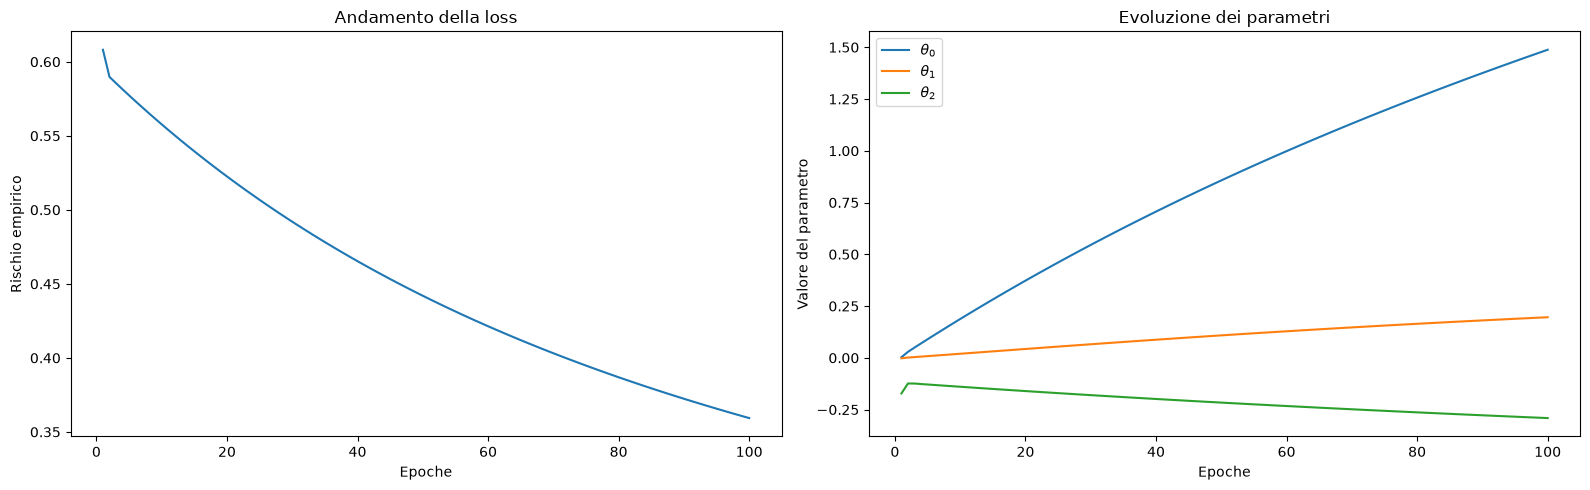

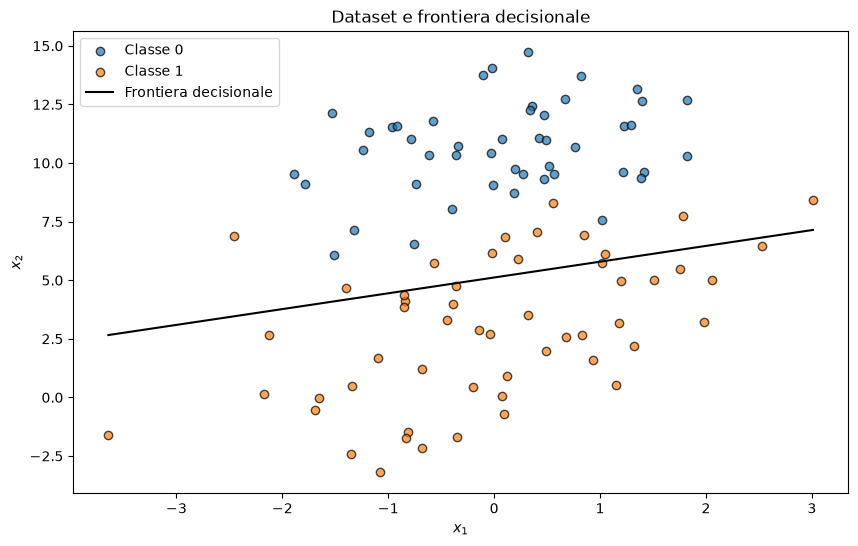

In [30]:
# ===========================================================
# Usiamo il GD tradizionale come riferimento per
# confrontare gli ottimizzatori avanzati.
#
# Tutti i metodi:
# - partono da theta = 0;
# - utilizzano lo stesso dataset;
# - calcolano il gradiente sull'intero dataset;
# - registrano la loss dopo ogni aggiornamento.
# ===========================================================

def batch_gd(X, t, eta=0.1, epochs=100):
    """
    Batch Gradient Descent standard.

    A ogni aggiornamento:
        g = gradiente medio del rischio empirico
        theta = theta - eta * g
    """

    d = X.shape[1]

    # Stessa inizializzazione degli altri ottimizzatori.
    theta = np.zeros((d, 1))

    cost_history = []
    theta_history = []

    for epoch in range(epochs):

        # Gradiente sull'intero dataset.
        g = gradient(theta, X, t)

        # Aggiornamento standard, senza memoria
        # e senza learning rate adattivo.
        theta -= eta * g

        # Registrazione dopo l'aggiornamento.
        theta_history.append(theta.copy())
        cost_history.append(cost(theta, X, t))

    return save_histories(cost_history, theta_history, d)


results["Batch GD"] = run_optimizer(
    "Batch GD", batch_gd,
    eta=0.1
)

### 🌀 Metodo del Momento (Momentum)

I metodi di discesa del gradiente visti finora possono diventare **inefficienti** quando la funzione di costo varia in modo molto diverso lungo direzioni diverse. Ad esempio, se la superficie del rischio empirico è una “vallata” allungata, gli aggiornamenti oscillano trasversalmente e convergono lentamente verso il minimo.

Per rendere la discesa più fluida, il **metodo del momento** introduce un concetto ispirato alla fisica: l’aggiornamento dei parametri è visto come il **moto di un corpo soggetto a inerzia** che scivola sulla superficie della funzione di costo $\mathcal{R}(\theta)$.

---

#### ⚙️ Idea fisica

Immagina che il vettore dei parametri $\theta$ rappresenti la **posizione** di una particella.  
Il gradiente $\nabla_\theta \mathcal{R}(\theta)$ agisce come una **forza** che la spinge verso il basso (verso il minimo).  
L’inerzia fa sì che, invece di fermarsi bruscamente, la particella **mantenga parte della velocità accumulata** nei passi precedenti.  
Il parametro $\gamma$ gioca il ruolo di **attrito**, regolando quanto della velocità precedente viene mantenuto.

---


#### 🧮 Formulazione matematica

Introduciamo un vettore di **velocità** $v^{(k)}$, che rappresenta lo spostamento dei parametri al passo $k$.

Indicando con $\hat R(\theta)$ il rischio empirico medio sul training set, l'aggiornamento è:

$$
\begin{aligned}
g^{(k)} &= \nabla_\theta \hat R(\theta^{(k)}) \\[4pt]
v^{(k+1)} &= \gamma v^{(k)} - \eta g^{(k)} \\[4pt]
\theta^{(k+1)} &= \theta^{(k)} + v^{(k+1)}
\end{aligned}
$$

dove:

- $\eta > 0$ è il **learning rate**;
- $\gamma \in [0,1)$ è il **coefficiente di momentum**, che determina quanta parte dello spostamento precedente viene conservata;
- $v^{(0)} = 0$ è la velocità iniziale.

Poiché utilizziamo Batch Gradient Descent, il gradiente è calcolato sull'intero dataset:

$$
\nabla_\theta \hat R(\theta)
=
\frac{1}{n}
\sum_{i=1}^{n}
\nabla_\theta L(h_\theta(x_i),t_i).
$$

Quando $\gamma=0$, otteniamo il Gradient Descent standard.

Quando $\gamma>0$, il nuovo aggiornamento combina il gradiente corrente con gli aggiornamenti precedenti.

---

#### 🔍 Interpretazione

- Se $\gamma = 0$, il metodo si riduce alla discesa del gradiente standard.  
- Se $\gamma > 0$, parte della direzione di aggiornamento precedente viene **conservata**, creando un effetto di **accelerazione** nelle direzioni coerenti del gradiente.  
- Se il gradiente cambia spesso direzione, l’inerzia tende a **smorzare le oscillazioni**, rendendo la discesa più stabile.

---

#### 📈 In sintesi

| Parametro | Significato | Effetto |
|------------|-------------|----------|
| $\eta$ | Learning rate | Controlla la velocità di aggiornamento |
| $\gamma$ | Fattore di momento | Controlla quanta “memoria” dei passi precedenti si mantiene |
| $v^{(k)}$ | Velocità | Direzione e intensità dello spostamento corrente |
| $\theta^{(k)}$ | Parametri | Posizione attuale nel paesaggio del rischio |

---

#### 🔹 Interpretazione vettoriale e aggiornamento ricorsivo

Mentre
$$
\theta^{(k)} = (\theta_1^{(k)}, \ldots, \theta_d^{(k)})^T
$$
rappresenta la **posizione** dei parametri al passo $k$,  
il vettore
$$
v^{(k)} = (v_1^{(k)}, \ldots, v_d^{(k)})^T
$$
rappresenta la **velocità di aggiornamento** che trasporta $\theta^{(k)}$ verso $\theta^{(k+1)}$.

---


#### 🔹 Dipendenza dai gradienti passati

Il principale vantaggio di Momentum è che ogni aggiornamento conserva una memoria dei gradienti precedenti.

Partendo dalla relazione:

$$
v^{(k+1)} = \gamma v^{(k)} - \eta g^{(k)}
$$

e assumendo $v^{(0)}=0$, possiamo sviluppare ricorsivamente:

$$
\begin{aligned}
v^{(1)} &= -\eta g^{(0)} \\[4pt]
v^{(2)} &= -\eta g^{(1)}-\eta\gamma g^{(0)} \\[4pt]
v^{(3)} &= -\eta g^{(2)}-\eta\gamma g^{(1)}
           -\eta\gamma^2 g^{(0)}.
\end{aligned}
$$

In generale:

$$
\boxed{
v^{(k+1)}
=
-\eta\sum_{r=0}^{k}
\gamma^{k-r}g^{(r)}
}
$$

e dunque:

$$
\theta^{(k+1)}
=
\theta^{(k)}
-
\eta\sum_{r=0}^{k}
\gamma^{k-r}g^{(r)}.
$$

I gradienti più recenti hanno peso maggiore, mentre l'influenza di quelli più vecchi diminuisce geometricamente.

**Interpretazione:** se i gradienti mantengono una direzione coerente, gli aggiornamenti si accumulano e possono accelerare la discesa. Se oscillano tra direzioni opposte, i loro contributi tendono a compensarsi.

---


#### 🔹 Applicazione alla regressione logistica

Nel nostro laboratorio utilizziamo un modello di regressione logistica:

$$
f(\theta,x_i)
=
\sigma(\theta_0+\theta_1x_{i1}+\theta_2x_{i2})
$$

dove la funzione sigmoide è:

$$
\sigma(z)=\frac{1}{1+e^{-z}}.
$$

Il rischio empirico è la binary cross-entropy media:

$$
\hat R(\theta)
=
-\frac{1}{n}\sum_{i=1}^{n}
\left[
t_i\log f(\theta,x_i)
+
(1-t_i)\log(1-f(\theta,x_i))
\right].
$$

Introduciamo $x_{i0}=1$ per includere il bias nel vettore dei parametri.

Il gradiente rispetto al parametro $\theta_j$ è:

$$
g_j^{(k)}
=
\frac{1}{n}\sum_{i=1}^{n}
\left(f(\theta^{(k)},x_i)-t_i\right)x_{ij},
\qquad j=0,1,2.
$$

L'aggiornamento con Momentum diventa:

$$
\boxed{
\begin{aligned}
v_j^{(k+1)}
&=
\gamma v_j^{(k)}
+
\frac{\eta}{n}
\sum_{i=1}^{n}
\left(t_i-f(\theta^{(k)},x_i)\right)x_{ij}
\\[5pt]
\theta_j^{(k+1)}
&=
\theta_j^{(k)}+v_j^{(k+1)}.
\end{aligned}
}
$$

In forma vettoriale, con $X$ matrice delle feature comprensiva della colonna di bias:

$$
\nabla_\theta\hat R(\theta)
=
\frac{1}{n}X^\top(f(\theta,X)-t).
$$

Questa è esattamente la formula utilizzata dalla funzione Python `gradient`.

---

#### 💡 Conclusione

- $v$ rappresenta la **velocità di aggiornamento**, che integra informazione storica dei gradienti.  
- $\gamma$ controlla **quanto del passato** viene mantenuto: valori più alti implicano più inerzia.  
- Ogni passo combina i gradienti precedenti con un effetto di **memoria esponenzialmente decrescente**, permettendo una convergenza **più rapida e stabile**.

### ⚙️ Varianti del Metodo del Momento e Segni degli Aggiornamenti

Il **metodo del momento** può essere implementato in diverse modalità, a seconda di **quanti esempi del dataset vengono usati per calcolare il gradiente ad ogni passo**.  
Il principio rimane lo stesso: si accumula una **velocità vettoriale** `v`, che tiene memoria della direzione di discesa.

---

#### 🔹 1️⃣ Batch Momentum

Nel **Batch Momentum**, ad ogni epoca si calcola il **gradiente medio** sull’intero dataset:

$$
v^{(k+1)} = \gamma v^{(k)} - \eta \, \nabla_\theta \overline{\mathcal{R}}(\theta^{(k)})
$$
$$
\theta^{(k+1)} = \theta^{(k)} + v^{(k+1)}
$$

Pseudocodice:

```
v = 0
for epoch in range(n_epochs):
    g = 0
    for k in range(dataset_size):
        g = g + evaluate_gradient(loss_function, theta, X[k])
    g = g / dataset_size          # gradiente medio
    v = gamma * v - eta * g       # aggiornamento della velocità
    theta = theta + v             # aggiornamento dei parametri
```

---

#### 🔹 2️⃣ Stochastic Momentum (SGD + Momentum)

Nel caso **stocastico**, ad ogni iterazione si utilizza **un solo campione (o mini-batch)** per stimare il gradiente.  
Il vantaggio è una maggiore velocità, ma con oscillazioni più evidenti:

```
v = 0
for epoch in range(n_epochs):
    for k in range(dataset_size):
        g = evaluate_gradient(loss_function, theta, X[k])
        v = gamma * v - eta * g
        theta = theta + v
```

---

#### 🔹 3️⃣ Interpretazione del segno

Nel termine di aggiornamento:

$$
v^{(k+1)} = \gamma v^{(k)} - \eta \, \nabla_\theta \mathcal{R}(\theta^{(k)})
$$

- Il segno **“−”** davanti al gradiente serve perché vogliamo **muoverci nella direzione opposta** al gradiente, ossia verso il minimo.  
- `v` memorizza la **direzione media di discesa**: se i gradienti successivi puntano nella stessa direzione, la velocità aumenta; se puntano in direzioni opposte, la velocità si attenua.

---

#### 🔹 4️⃣ Ruolo del parametro γ (gamma)

Il parametro **γ ∈ [0,1)** determina **quanto del passo precedente viene mantenuto**:

| γ | Significato | Effetto pratico |
|:--:|:-------------|:----------------|
| 0 | nessuna memoria → discesa del gradiente standard | Aggiornamenti lenti, ma stabili |
| 0.5–0.9 | memoria moderata | Convergenza più rapida |
| >0.9 | forte inerzia | Rischio di overshooting o oscillazioni |

---

#### 💡 In sintesi

- `v` rappresenta una **media pesata dei gradienti passati** → effetto di inerzia.  
- Il termine `γ v` **mantiene una frazione della velocità precedente**.  
- Il termine `−η ∇R(θ)` **spinge nella direzione opposta al gradiente**.  
- L’aggiornamento finale `θ = θ + v` sposta i parametri **verso il minimo**, seguendo la direzione “smussata” nel tempo.


=== Momentum ===
Tempo: 0.0042 s
Aggiornamenti: 100
Loss finale: 0.097665
Theta finale: [11.79008935  1.06316804 -1.65092745]


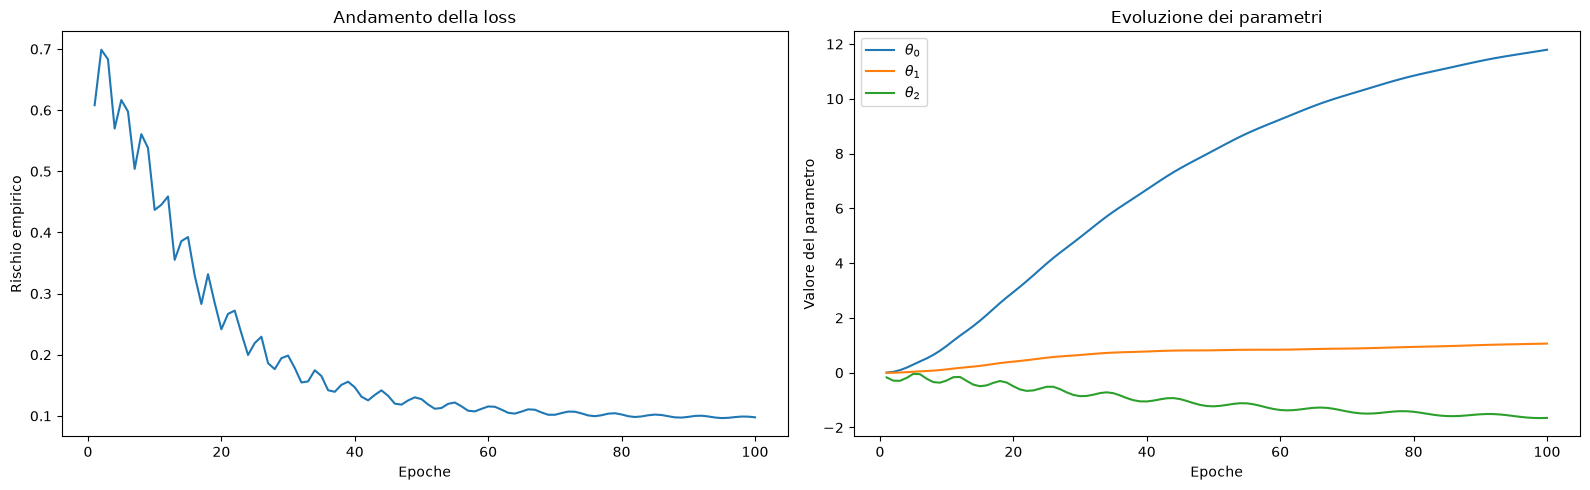

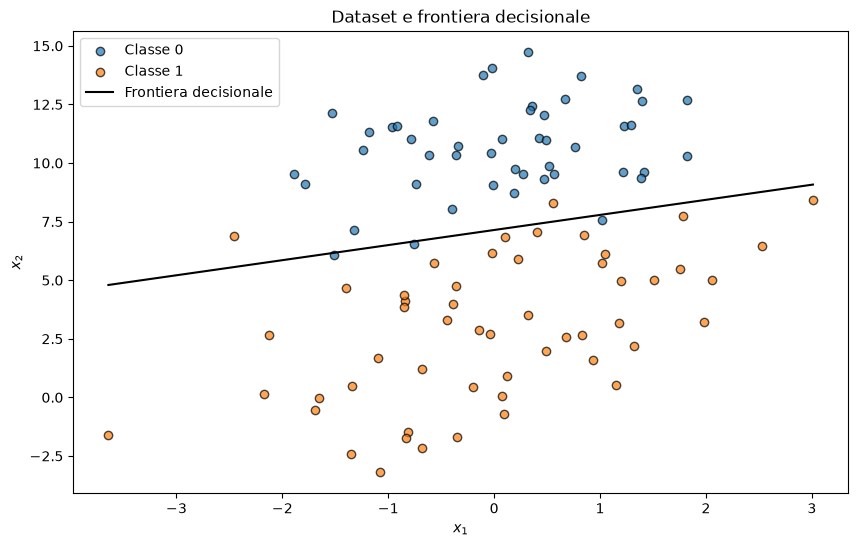

In [31]:

def momentum_gd(X, t, eta=0.1, gamma=0.9, epochs=1000):
    """
    Batch Gradient Descent con Momentum.

    eta   : learning rate
    gamma : frazione della velocità precedente conservata

    A ogni iterazione:
        g = gradiente del rischio empirico
        v = gamma * v - eta * g
        theta = theta + v
    """

    # Numero di parametri, incluso il bias.
    d = X.shape[1]

    # Tutti gli ottimizzatori partono da theta = 0:
    # in questo modo confrontiamo gli algoritmi usando
    # la stessa inizializzazione.
    theta = np.zeros((d, 1))

    # Velocità inizialmente nulla: non abbiamo ancora
    # effettuato nessun aggiornamento.
    v = np.zeros_like(theta)

    # Memorizziamo loss e parametri dopo ogni aggiornamento.
    cost_history, theta_history = [], []

    for epoch in range(epochs):

        # 1. Calcoliamo il gradiente BATCH:
        #    usa tutti gli esempi del training set.
        g = gradient(theta, X, t)

        # 2. Aggiorniamo la velocità.
        #    gamma * v conserva parte dello spostamento
        #    precedente (memoria / inerzia).
        #
        #    -eta * g rappresenta il contributo del
        #    gradiente corrente, in direzione di discesa.
        v = gamma * v - eta * g

        # 3. Aggiorniamo i parametri usando la velocità.
        #    Con gamma = 0 torniamo al GD standard.
        theta = theta + v

        # 4. Registriamo i valori DOPO l'aggiornamento.
        #
        #    .copy() è importante:
        #    vogliamo salvare una fotografia dei parametri
        #    di questa iterazione, indipendente da
        #    eventuali modifiche successive.
        theta_history.append(theta.copy())

        # Valutiamo la loss sull'intero dataset.
        cost_history.append(cost(theta, X, t))

    return save_histories(cost_history, theta_history, d)


# Passiamo a run_optimizer il riferimento alla funzione
# momentum_gd, non il risultato di momentum_gd(...).
#
# run_optimizer la chiamerà con X, t, epochs, eta e gamma.
results["Momentum"] = run_optimizer(
    "Momentum", momentum_gd,
    eta=0.1, gamma=0.97
)

### ⚡ Accelerazione del Gradiente di Nesterov (Nesterov Momentum)

Il metodo di **Nesterov** nasce come una raffinata estensione del **metodo del momento**.  
L’idea chiave è introdurre un *“passo di anticipo”* (*look-ahead*): invece di calcolare il gradiente nel punto corrente, lo si valuta **in una posizione predetta** più avanti lungo la direzione di velocità attuale.

---


#### 🔹 Intuizione di base

Nel Momentum classico il gradiente viene valutato nella posizione corrente $\theta^{(k)}$.

Nesterov introduce un'idea differente: prima di calcolare il gradiente, considera la posizione in cui i parametri arriverebbero seguendo soltanto il movimento già accumulato.

Questa posizione anticipata (*look-ahead*) è:

$$
\boxed{
\tilde\theta^{(k)}
=
\theta^{(k)}+\gamma v^{(k)}
}
$$

Il gradiente viene quindi valutato in $\tilde\theta^{(k)}$, anziché in $\theta^{(k)}$.

#### 🔹 Regola di aggiornamento

Il metodo Nesterov Accelerated Gradient (NAG), nella variante implementata in questo laboratorio, esegue:

$$
\begin{aligned}
\tilde\theta^{(k)}
&=
\theta^{(k)}+\gamma v^{(k)}
\\[5pt]
g^{(k)}
&=
\nabla_\theta\hat R(\tilde\theta^{(k)})
\\[5pt]
v^{(k+1)}
&=
\gamma v^{(k)}-\eta g^{(k)}
\\[5pt]
\theta^{(k+1)}
&=
\theta^{(k)}+v^{(k+1)}.
\end{aligned}
$$

La differenza fondamentale rispetto a Momentum è **il punto nel quale viene valutato il gradiente**:

| Metodo | Punto di valutazione del gradiente |
|---|---|
| Momentum | $\theta^{(k)}$ |
| Nesterov | $\theta^{(k)}+\gamma v^{(k)}$ |

Questa anticipazione può ridurre l'overshooting e migliorare la convergenza, a seconda della funzione obiettivo e degli iperparametri.

**Nota computazionale:** la nostra implementazione calcola un solo gradiente per aggiornamento, esattamente come Momentum. Cambia il punto di valutazione, non il numero di gradienti calcolati.


---

#### 🔹 Interpretazione geometrica

- Invece di “muoversi alla cieca” lungo il gradiente nel punto corrente,  
  Nesterov **guarda leggermente avanti** per valutare come cambierà la funzione di costo.  
- Questo permette di **correggere la direzione prima di eseguire il passo**, evitando eccessive oscillazioni.

---

#### 🔹 Confronto con il Momentum classico

| Metodo | Punto in cui viene calcolato il gradiente | Effetto |
|---------|-------------------------------------------|----------|
| Momentum | $\theta^{(k)}$ | Lento ad adattarsi alle variazioni del gradiente |
| Nesterov | $\theta^{(k)} + \gamma v^{(k)}$ | Anticipa la direzione → più stabile e rapido |

---

#### 🔹 Forma espansa (dipendenza dai gradienti passati)

Partendo da:
$$
\theta^{(k+1)} = \theta^{(k)} + v^{(k+1)} = \theta^{(k)} + \gamma v^{(k)} - \eta \nabla_\theta \mathcal{R}(\tilde{\theta}^{(k)})
$$
possiamo osservare che il nuovo aggiornamento **anticipa** il contributo del gradiente,  
ottenendo così un movimento più “intelligente” verso il minimo.

---

#### 💡 In sintesi

- **Momentum** valuta il gradiente nel punto corrente $\theta^{(k)}$ e conserva una parte degli aggiornamenti precedenti.
- **Nesterov** valuta il gradiente nel punto anticipato $\theta^{(k)}+\gamma v^{(k)}$.
- Il *look-ahead* permette di incorporare informazioni sulla pendenza nella posizione verso cui l'inerzia sta spingendo i parametri.
- Questo può ridurre l'overshooting e accelerare la convergenza, ma **non garantisce prestazioni migliori di Momentum per ogni funzione obiettivo e scelta degli iperparametri**.

Entrambi i metodi utilizzano un gradiente per aggiornamento. Cambia il punto in cui viene valutato.


---

![Confronto tra Momentum e Nesterov Momentum.](https://tvml.github.io/ml2425/codici/assets/nesterov.png)

#### Pseudocodice
```python
v = np.zeros_like(theta)

for epoch in range(n_epochs):
    theta_lookahead = theta + gamma * v

    # Gradiente medio calcolato nel punto anticipato
    g = gradient(theta_lookahead, X, t)

    v = gamma * v - eta * g
    theta = theta + v
```
----


=== Nesterov ===
Tempo: 0.0026 s
Aggiornamenti: 100
Loss finale: 0.097712
Theta finale: [11.10071305  1.00605578 -1.51862603]


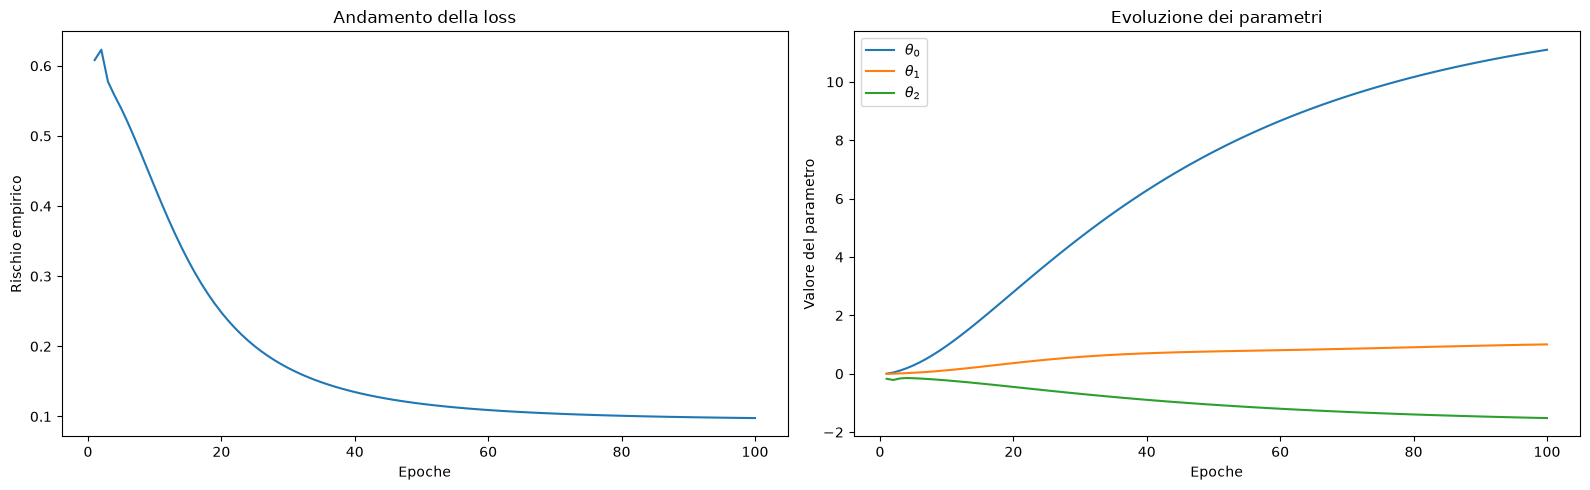

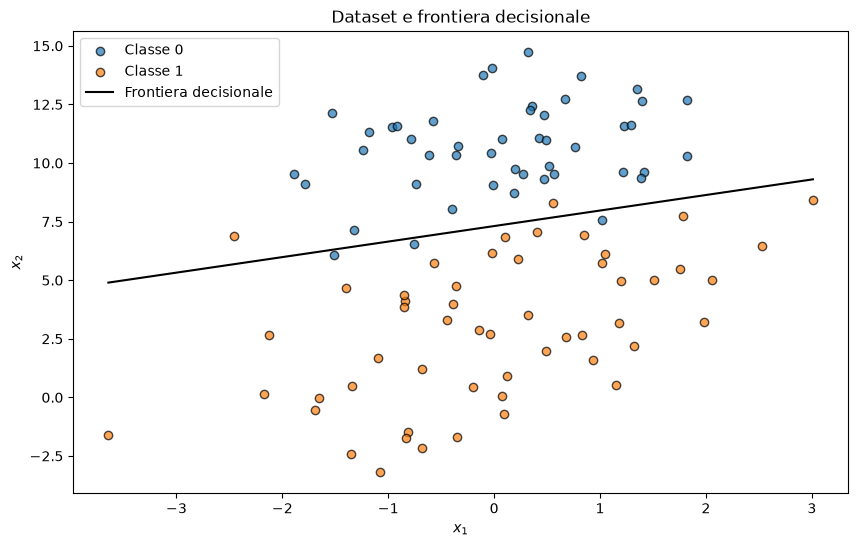

In [32]:

def nesterov_gd(X, t, eta=0.1, gamma=0.97,
                epochs=1000):
    """
    Batch Gradient Descent con accelerazione di Nesterov.

    La differenza rispetto al Momentum classico è il
    punto in cui viene calcolato il gradiente:

        Momentum : g = gradient(theta, X, t)
        Nesterov : g = gradient(theta + gamma*v, X, t)
    """

    # Numero di parametri del modello.
    d = X.shape[1]

    # Parametri e velocità iniziali.
    theta = np.zeros((d, 1))
    v = np.zeros_like(theta)

    # Storico dei risultati.
    cost_history, theta_history = [], []

    for epoch in range(epochs):

        # 1. LOOK-AHEAD
        #    Calcoliamo dove arriverebbero i parametri
        #    se seguissimo soltanto la velocità accumulata,
        #    senza considerare il nuovo gradiente.
        theta_lookahead = theta + gamma * v

        # 2. Calcoliamo il gradiente nel punto ANTICIPATO.
        #    Questo è il passaggio che distingue Nesterov
        #    dal Momentum classico.
        g = gradient(theta_lookahead, X, t)

        # 3. Aggiorniamo la velocità usando il gradiente
        #    valutato nel punto look-ahead.
        v = gamma * v - eta * g

        # 4. Aggiorniamo i parametri effettivi.
        theta = theta + v

        # 5. Monitoriamo il rischio empirico e i parametri
        #    dopo l'aggiornamento.
        theta_history.append(theta.copy())
        cost_history.append(cost(theta, X, t))

    return save_histories(cost_history, theta_history, d)


results["Nesterov"] = run_optimizer(
    "Nesterov", nesterov_gd,
    eta=0.1, gamma=0.97
)


### ⚙️ Adagrad — Adaptive Gradient Descent

Adagrad introduce un **learning rate adattivo per ciascun parametro**, basato sulla somma cumulativa dei quadrati dei gradienti.

L'obiettivo è compensare le differenze nella scala e nella frequenza dei gradienti associati alle diverse feature.

---

#### 🔹 Accumulazione dei gradienti

Adagrad introduce un accumulatore separato per ogni parametro $\theta_j$.

Indichiamo con:

$$
g_{j,k}
=
\frac{\partial\hat R(\theta)}
{\partial\theta_j}
\bigg|_{\theta=\theta^{(k)}}
$$

la componente $j$ del gradiente al passo $k$.

Partendo da $G_{j,-1}=0$, l'accumulatore è aggiornato mediante:

$$
\boxed{
G_{j,k}
=
G_{j,k-1}+g_{j,k}^2
}
$$

Equivalentemente:

$$
G_{j,k}
=
\sum_{r=0}^{k}g_{j,r}^2.
$$

I quadrati impediscono che gradienti positivi e negativi si cancellino.

#### 🔹 Learning rate adattivo

Adagrad utilizza un learning rate effettivo differente per ogni parametro:

$$
\boxed{
\eta_{j,k}
=
\frac{\eta}{\sqrt{G_{j,k}}+\varepsilon}
}
$$

dove $\varepsilon>0$ è una piccola costante per la stabilità numerica.

L'aggiornamento è:

$$
\theta_j^{(k+1)}
=
\theta_j^{(k)}
-
\eta_{j,k}g_{j,k}.
$$

In forma compatta:

$$
\boxed{
\theta^{(k+1)}
=
\theta^{(k)}
-
\eta
\frac{g^{(k)}}{\sqrt{G^{(k)}}+\varepsilon}
}
$$

La divisione, la radice quadrata e il quadrato sono applicati **componente per componente**.

#### 🔹 Interpretazione

- Se una coordinata ha accumulato gradienti grandi, il suo learning rate effettivo diminuisce.
- Se una coordinata riceve gradienti piccoli o poco frequenti, il learning rate diminuisce più lentamente.
- L'accumulatore $G_{j,k}$ non può diminuire: di conseguenza, il learning rate effettivo non aumenta durante l'addestramento.

Questo comportamento è utile in presenza di feature sparse, ma può rendere i passi progressivamente troppo piccoli.

Il learning rate effettivo tende a zero quando l'accumulatore cresce senza limite; ciò non è inevitabile se la somma dei quadrati dei gradienti rimane finita.

---


#### 🔹 Limite del metodo

Poiché l'accumulatore di Adagrad è una somma cumulativa di quadrati,

$$
G_{j,k}=\sum_{r=0}^{k}g_{j,r}^2,
$$

esso non può diminuire.

Il learning rate effettivo

$$
\eta_{j,k}
=
\frac{\eta}{\sqrt{G_{j,k}}+\varepsilon}
$$

è quindi **monotono non crescente**.

Se i gradienti continuano a produrre contributi significativi, l'accumulatore cresce e il learning rate effettivo può diventare molto piccolo, rallentando notevolmente l'ottimizzazione.

Se invece la somma dei quadrati dei gradienti converge a un valore finito, il learning rate effettivo non deve necessariamente tendere a zero.

**Il limite pratico di Adagrad non è che il learning rate debba sempre annullarsi, ma che non possa aumentare nuovamente quando la scala dei gradienti diminuisce.**

Questa osservazione motiva RMSProp, che sostituisce l'accumulazione permanente con una media mobile esponenziale.


---

#### 💡 In sintesi

| Concetto | Significato |
|-----------|-------------|
| $G_{j,k}$ | Somma cumulativa dei quadrati dei gradienti del parametro $j$ |
| $\eta_j^{(k)}$ | Learning rate adattivo (decrescente nel tempo) |
| $\varepsilon$ | Costante di stabilizzazione numerica |
| ✅ Vantaggio | Adattamento automatico del passo per ogni direzione |
| ⚠️ Limite | Learning rate che tende a zero nel lungo periodo |

---

In pratica, **Adagrad** è ottimo per:
- feature con scale molto diverse,
- dati sparsi (es. parole rare nei modelli NLP).

Ma, poiché il passo decresce troppo nel tempo, è stato poi esteso nei metodi **RMSProp** e **Adam**, che introducono meccanismi di *decadimento controllato* per mantenere il learning rate efficace più a lungo.


=== Adagrad ===
Tempo: 0.0028 s
Aggiornamenti: 100
Loss finale: 0.330393
Theta finale: [ 1.75728038  0.28258097 -0.32479122]


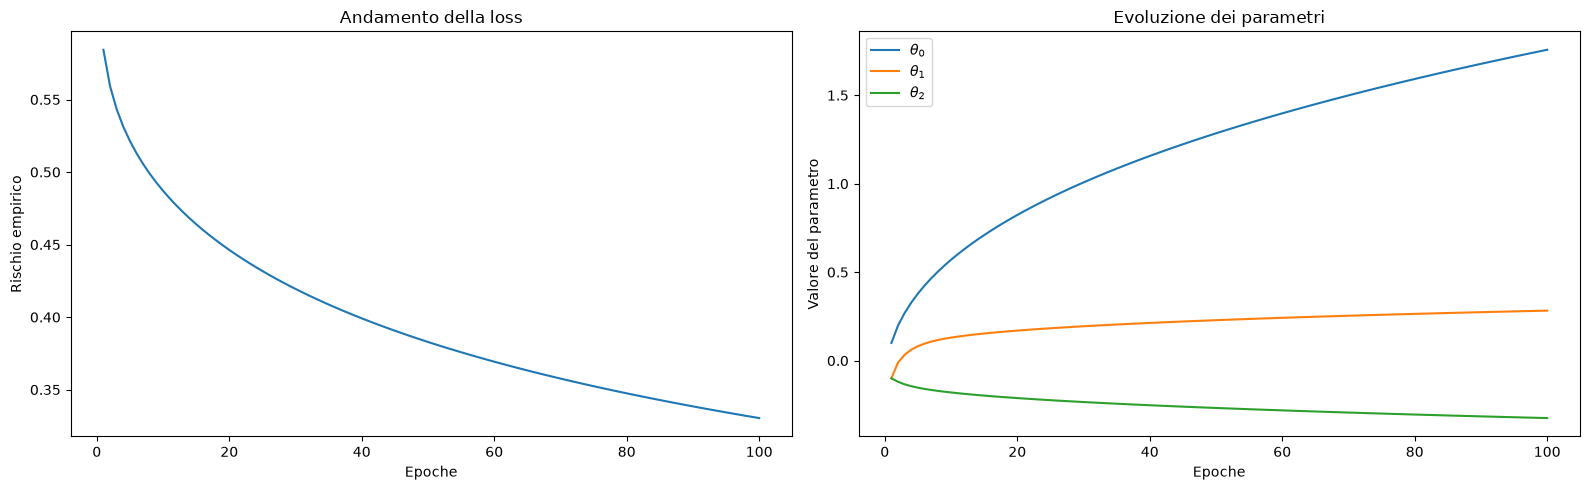

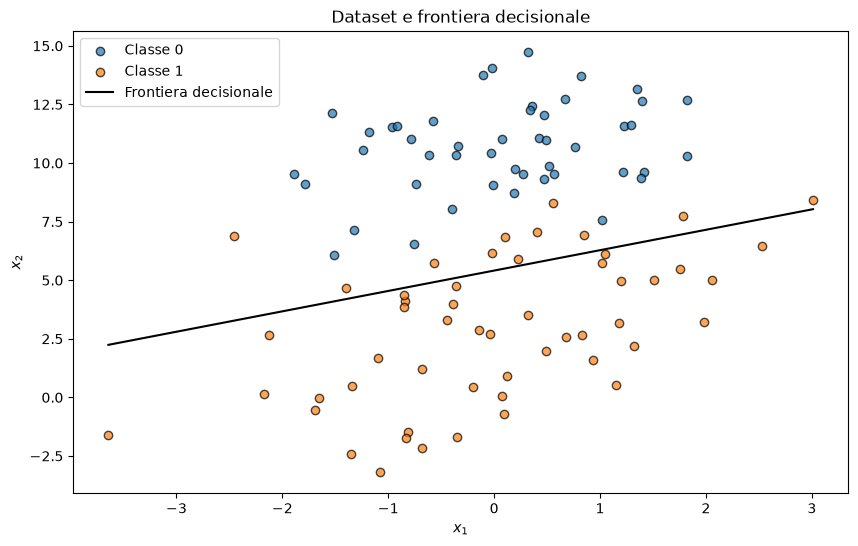

In [33]:

def adagrad(X, t, eta=0.1, eps=1e-8, epochs=1000):
    """
    Batch Gradient Descent con Adagrad.

    A ogni parametro è associato un accumulatore G
    contenente la somma dei quadrati dei suoi gradienti.

    Le coordinate con gradienti storicamente grandi
    ricevono un learning rate effettivo più piccolo.
    """

    # Numero di parametri, incluso il bias.
    d = X.shape[1]

    # Inizializzazione dei parametri.
    theta = np.zeros((d, 1))

    # Un accumulatore per ogni parametro.
    # G[j] conterrà la somma dei quadrati dei gradienti
    # osservati fino all'iterazione corrente.
    G = np.zeros_like(theta)

    cost_history, theta_history = [], []

    for epoch in range(epochs):

        # 1. Gradiente del rischio empirico su tutti i dati.
        g = gradient(theta, X, t)

        # 2. Accumuliamo i gradienti AL QUADRATO.
        #
        #    Il quadrato evita la cancellazione tra valori
        #    positivi e negativi e misura la grandezza
        #    dei gradienti osservati nel tempo.
        #
        #    G += g**2 equivale a G = G + g**2.
        G += g**2

        # 3. Aggiornamento adattivo, coordinata per coordinata.
        #
        #    eta / (sqrt(G[j]) + eps) è il learning rate
        #    effettivo del parametro theta[j].
        #
        #    Poiché G non diminuisce mai, il learning rate
        #    effettivo non può aumentare.
        #
        #    eps evita divisioni per zero.
        theta -= eta * g / (np.sqrt(G) + eps)

        # 4. Registriamo lo stato dopo l'aggiornamento.
        theta_history.append(theta.copy())
        cost_history.append(cost(theta, X, t))

    return save_histories(cost_history, theta_history, d)


results["Adagrad"] = run_optimizer(
    "Adagrad", adagrad,
    eta=0.1, eps=1e-8
)

### RMSProp

### ⚙️ RMSProp — Root Mean Square Propagation

Il metodo **RMSProp** nasce per risolvere un limite importante di **Adagrad**:  in Adagrad, la somma cumulativa dei quadrati dei gradienti cresce continuamente, facendo sì che il learning rate diminuisca **monotonicamente fino quasi ad annullarsi**.  

RMSProp introduce una **media mobile esponenziale** dei gradienti al posto della somma totale, così da mantenere un equilibrio tra adattività e stabilità.

---

#### 🔹 Idea principale

In Adagrad, il termine cumulativo era:

$$
G_{j,k} = \sum_{i=0}^{k} g_{j,i}^2
$$

che cresce indefinitamente nel tempo.  
RMSProp sostituisce questa somma con una **media pesata dei gradienti recenti**,  
dove i contributi passati **decadono esponenzialmente** grazie a un parametro di smorzamento $\gamma$:

$$
\tilde{G}_{j,k} = \gamma \, \tilde{G}_{j,k-1} + (1 - \gamma) g_{j,k}^2
$$

dove $0 < \gamma < 1$.  
Valori di $\gamma$ tipici sono intorno a **0.9**.

---

#### 🔹 Espansione della media mobile

Sviluppando ricorsivamente la formula si ottiene:

$$
\tilde{G}_{j,k} = (1 - \gamma) \sum_{i=0}^{k} \gamma^{k-i} g_{j,i}^2
$$

Questa è una **media geometrica pesata**: i gradienti recenti pesano di più, quelli passati perdono importanza in modo esponenziale.  
Si assume $\tilde{G}_{j,k} = 0$ per $k < 0$.

---


#### 🔹 Aggiornamento dei parametri

A differenza di Adagrad, RMSProp non conserva una somma cumulativa di tutti i gradienti al quadrato.

Utilizza una **media mobile esponenziale dei quadrati dei gradienti**, che assegna maggiore importanza ai valori recenti.

Con $\tilde G_{j,-1}=0$:

$$
\boxed{
\tilde G_{j,k}
=
\gamma\tilde G_{j,k-1}
+
(1-\gamma)g_{j,k}^2
}
$$

dove $\gamma\in(0,1)$ controlla la memoria dell'accumulatore.

Sviluppando la ricorrenza:

$$
\tilde G_{j,k}
=
(1-\gamma)
\sum_{r=0}^{k}
\gamma^{k-r}g_{j,r}^2.
$$

L'aggiornamento dei parametri è:

$$
\boxed{
\theta_j^{(k+1)}
=
\theta_j^{(k)}
-
\frac{\eta}
{\sqrt{\tilde G_{j,k}}+\varepsilon}
g_{j,k}
}
$$

#### 🔹 Interpretazione

- Gradienti recenti di grande intensità aumentano $\tilde G_{j,k}$ e riducono il passo effettivo.
- Quando i gradienti diventano più piccoli, anche $\tilde G_{j,k}$ può diminuire.
- Il learning rate effettivo può quindi aumentare nuovamente, a differenza di Adagrad.

RMSProp evita la riduzione monotona del learning rate tipica di Adagrad, ma non garantisce un passo costante né una convergenza più rapida in ogni problema.


---

#### 💡 In sintesi

| Concetto | Significato |
|-----------|-------------|
| $\tilde{G}_{j,k}$ | Media mobile dei quadrati dei gradienti (decadimento esponenziale) |
| $\gamma$ | Fattore di smorzamento, controlla la memoria dei gradienti passati |
| $\varepsilon$ | Evita divisioni per zero e stabilizza l’aggiornamento |
| Vantaggio | Mantiene un learning rate efficace anche dopo molte iterazioni |
| Differenza da Adagrad | Usa una media mobile invece di una somma cumulativa |

---

RMSProp è quindi una **versione “a memoria corta” di Adagrad**, che bilancia adattività e velocità di convergenza.  È ampiamente usato come base per metodi più avanzati, come **Adam** e **Adadelta**.




=== RMSProp ===
Tempo: 0.0028 s
Aggiornamenti: 100
Loss finale: 0.136446
Theta finale: [ 6.56393941  0.72431026 -0.87742189]


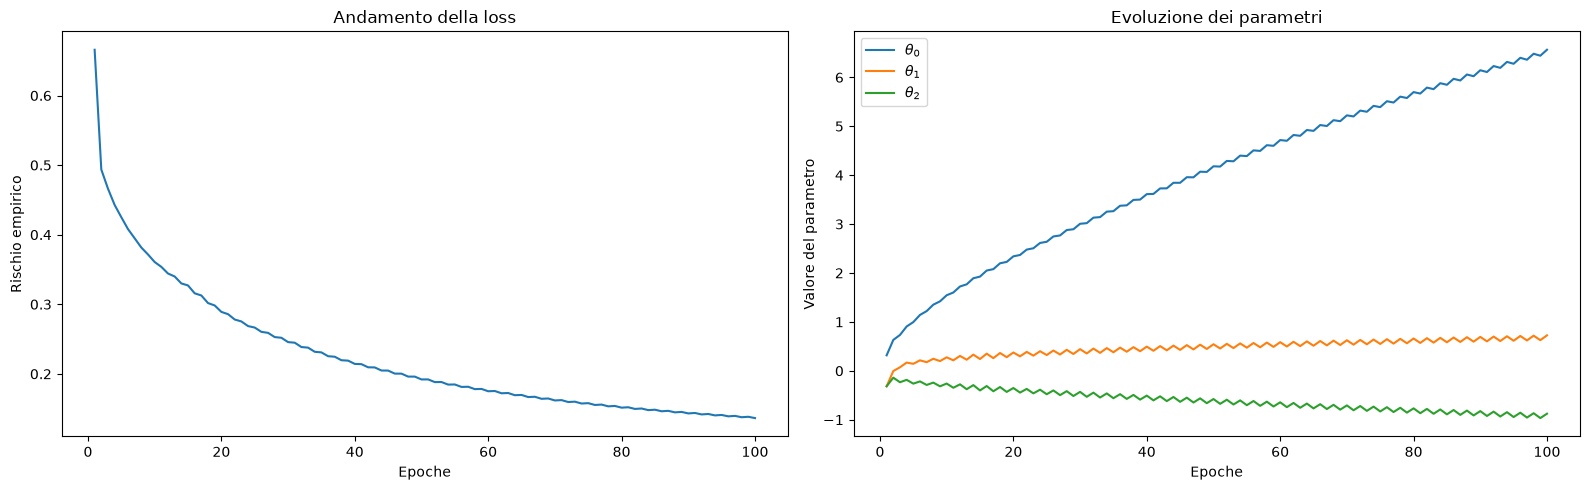

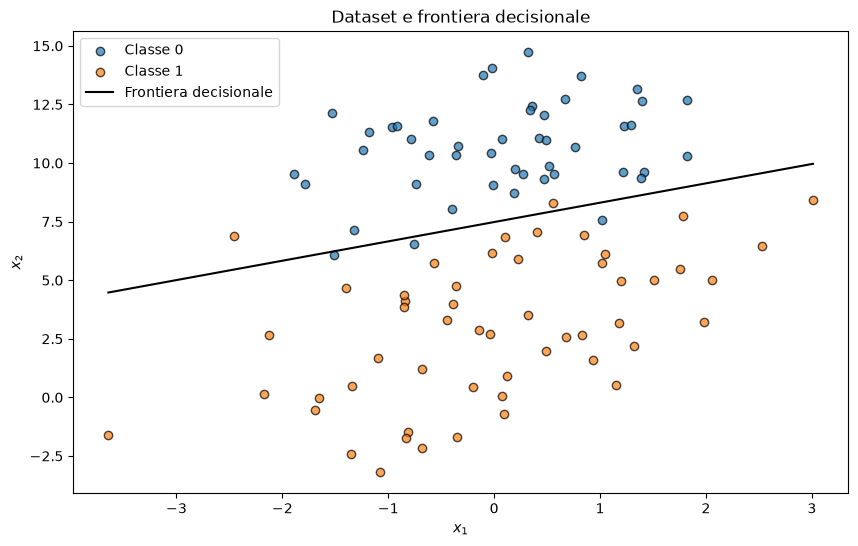

In [34]:

def RMSProp(X, t, eta=0.1, gamma=0.9,
            eps=1e-8, epochs=1000):
    """
    Batch Gradient Descent con RMSProp.

    A differenza di Adagrad, non accumula tutti i
    quadrati dei gradienti in una somma crescente.

    Utilizza una media mobile esponenziale:
    i gradienti recenti hanno maggiore influenza,
    quelli più lontani vengono progressivamente
    dimenticati.
    """

    d = X.shape[1]

    # Inizializzazione dei parametri.
    theta = np.zeros((d, 1))

    # Memoria della scala recente dei gradienti:
    # contiene una media mobile dei gradienti al quadrato.
    G_tilde = np.zeros_like(theta)

    cost_history, theta_history = [], []

    for epoch in range(epochs):

        # 1. Gradiente batch nel punto corrente.
        g = gradient(theta, X, t)

        # 2. Media mobile esponenziale dei gradienti
        #    al quadrato.
        #
        #    gamma * G_tilde:
        #       conserva parte della memoria precedente.
        #
        #    (1 - gamma) * g**2:
        #       introduce l'informazione del nuovo gradiente.
        #
        #    A differenza della somma di Adagrad,
        #    questa media può anche diminuire.
        G_tilde = (
            gamma * G_tilde + (1 - gamma) * g**2
        )

        # 3. Learning rate adattivo per ogni parametro.
        #
        #    Se la media dei quadrati è grande,
        #    l'aggiornamento viene ridotto.
        #
        #    Se la media diminuisce, il learning rate
        #    effettivo può aumentare nuovamente.
        theta -= eta * g / (np.sqrt(G_tilde) + eps)

        # 4. Registrazione dei risultati.
        theta_history.append(theta.copy())
        cost_history.append(cost(theta, X, t))

    return save_histories(cost_history, theta_history, d)


results["RMSProp"] = run_optimizer(
    "RMSProp", RMSProp,
    eta=0.1, gamma=0.9, eps=1e-8
)

#### 🔹 Limiti di RMSProp e motivazione di Adadelta

Nonostante RMSProp risolva il problema del *learning rate che tende a zero* di Adagrad,  
esso **richiede ancora di scegliere manualmente un valore di $\eta$**, che può essere critico:  
- se $\eta$ è troppo grande → il training diventa instabile,  
- se è troppo piccolo → la convergenza è lenta.

Inoltre, RMSProp **non adatta direttamente la scala degli aggiornamenti**:  
ogni parametro si muove in base al gradiente recente, ma senza tenere conto  
di *quanto* si è effettivamente mosso in passato.

👉 **Adadelta** nasce proprio per superare questi due limiti:
- elimina completamente la dipendenza esplicita da $\eta$,
- introduce una stima dinamica anche della **scala degli aggiornamenti**.

### ⚙️ Adadelta — Apprendimento adattivo senza learning rate fisso

**Adadelta** è un’evoluzione di **RMSProp** progettata per rendere l’ottimizzazione ancora più automatica e stabile.  
Nasce con due obiettivi principali:
1. Evitare di dover scegliere manualmente un learning rate $\eta$.
2. Impedire che il passo di aggiornamento si riduca troppo nel tempo, come accade in Adagrad e, in parte, in RMSProp.

In sostanza, Adadelta impara **da solo** quanto “forte” deve essere ogni passo,  
usando esclusivamente informazioni già presenti nei gradienti e negli aggiornamenti precedenti.

---

#### 🔹 Dalla logica di RMSProp all’idea di Adadelta

RMSProp correggeva il limite di Adagrad introducendo una **media mobile dei gradienti recenti**, così da evitare che il learning rate diminuisse all’infinito.  
Tuttavia, RMSProp **mantiene ancora un $\eta$ fisso**, scelto a mano,
e non tiene conto di quanto i parametri si siano mossi realmente.

Adadelta risolve entrambe le questioni:
- **elimina il learning rate globale $\eta$**,  
- e introduce una seconda “memoria” che misura **quanto grandi sono stati gli aggiornamenti effettivi** dei parametri.

Così, il metodo confronta:
- la *forza* con cui il modello vuole cambiare (i gradienti),  
- con *quanto si è già mosso in passato* (gli aggiornamenti).

👉 Se i gradienti sono forti, Adadelta riduce il passo; se sono deboli, lo aumenta.  

Tutto accade automaticamente, senza parametri da regolare.

---


#### 🔹 Come funziona Adadelta

Adadelta introduce due accumulatori per ciascun parametro:

- $\tilde G_{j,k}$: media mobile dei quadrati dei gradienti;
- $\overline G_{j,k}$: media mobile dei quadrati degli aggiornamenti.

Entrambi sono inizializzati a zero prima della prima iterazione:

$$
\tilde G_{j,-1}=0,
\qquad
\overline G_{j,-1}=0.
$$

**1. Calcolo del gradiente**

$$
g_{j,k}
=
\frac{\partial\hat R(\theta)}
{\partial\theta_j}
\bigg|_{\theta=\theta^{(k)}}.
$$

**2. Aggiornamento della memoria dei gradienti**

$$
\tilde G_{j,k}
=
\gamma\tilde G_{j,k-1}
+
(1-\gamma)g_{j,k}^2.
$$

**3. Calcolo dell'incremento**

$$
\boxed{
\Delta_{j,k}
=
-
\frac{
\sqrt{\overline G_{j,k-1}+\varepsilon}
}{
\sqrt{\tilde G_{j,k}+\varepsilon}
}
g_{j,k}
}
$$

Il numeratore misura la scala degli aggiornamenti precedenti; il denominatore misura la scala recente dei gradienti.

**4. Aggiornamento della memoria degli incrementi**

$$
\overline G_{j,k}
=
\gamma\overline G_{j,k-1}
+
(1-\gamma)\Delta_{j,k}^2.
$$

**5. Aggiornamento dei parametri**

$$
\boxed{
\theta_j^{(k+1)}
=
\theta_j^{(k)}+\Delta_{j,k}
}
$$

**Perché utilizziamo $\overline G_{j,k-1}$?**

Perché $\overline G_{j,k}$ dipende dall'incremento $\Delta_{j,k}$ che stiamo ancora calcolando.

Al primo passo, l'accumulatore degli incrementi è nullo, ma il termine $\varepsilon$ permette comunque di ottenere un incremento non nullo quando il gradiente è non nullo.

Adadelta non richiede un learning rate globale esplicito nella formulazione qui implementata, ma rimangono da scegliere gli iperparametri $\gamma$ ed $\varepsilon$.


---

#### 🔹 Il ruolo del parametro $\gamma$

Il parametro $\gamma$ (o $\rho$) decide **quanta memoria** tenere del passato:

- **$\gamma$ alto (0.95–0.99)** → memoria lunga → aggiornamenti stabili ma lenti.  
- **$\gamma$ basso (0.8–0.9)** → memoria corta → aggiornamenti rapidi ma più rumorosi.

👉 In pratica, $\gamma$ regola la “memoria temporale” del metodo.  
Valori attorno a **0.9–0.95** sono un buon compromesso.

---

#### 💡 In sintesi

| Concetto | Significato |
|-----------|-------------|
| $\tilde{G}_{j,k}$ | Media mobile dei quadrati dei gradienti |
| $\overline{G}_{j,k}$ | Media mobile dei quadrati degli aggiornamenti |
| $\gamma$ | Fattore di smorzamento (controlla la memoria) |
| $\varepsilon$ | Termine di stabilizzazione numerica |
| ✅ Vantaggio | Nessun learning rate fisso; passo che si autoregola |
| ⚙️ Effetto | Aggiornamenti stabili e consistenti nel tempo |

---

In breve, **Adadelta** è un *RMSProp autobilanciato*:  usa la memoria sia dei gradienti che dei passi per regolare automaticamente la scala degli aggiornamenti,  rendendo l’apprendimento **stabile, robusto e completamente automatico**,  senza mai scegliere manualmente il valore di $\eta$.

In [35]:

def Adadelta(X, t, gamma=0.9, eps=1e-8,
             epochs=1000):
    """
    Batch Gradient Descent con Adadelta.

    Il metodo utilizza due memorie:
    - G_tilde: media mobile dei gradienti al quadrato;
    - G_over: media mobile degli aggiornamenti al quadrato.

    Nella variante implementata non è presente un
    learning rate globale eta esplicito.
    """

    d = X.shape[1]

    # Inizializzazione dei parametri.
    theta = np.zeros((d, 1))

    # Prima memoria: grandezza dei gradienti recenti.
    G_tilde = np.zeros_like(theta)

    # Seconda memoria: grandezza degli spostamenti
    # realmente effettuati nelle iterazioni precedenti.
    G_over = np.zeros_like(theta)

    cost_history, theta_history = [], []

    for epoch in range(epochs):

        # 1. Gradiente batch del rischio empirico.
        g = gradient(theta, X, t)

        # 2. Aggiorniamo la media mobile dei quadrati
        #    dei gradienti.
        #
        #    Questo passaggio è analogo a RMSProp.
        G_tilde = (
            gamma * G_tilde + (1 - gamma) * g**2
        )

        # 3. Calcoliamo l'incremento dei parametri.
        #
        #    NUMERATORE:
        #    sqrt(G_over + eps) misura la scala
        #    degli aggiornamenti precedenti.
        #
        #    DENOMINATORE:
        #    sqrt(G_tilde + eps) misura la scala
        #    recente dei gradienti.
        #
        #    Il rapporto adatta automaticamente il passo.
        #
        #    IMPORTANTE: G_over qui contiene soltanto
        #    gli incrementi PASSATI, non quello corrente,
        #    che dobbiamo ancora calcolare.
        delta = (
            -np.sqrt(G_over + eps)
            / np.sqrt(G_tilde + eps) * g
        )

        # 4. Ora che conosciamo delta possiamo
        #    aggiornare la memoria degli incrementi.
        #
        #    L'ordine delle operazioni è importante:
        #    prima calcoliamo delta, poi aggiorniamo G_over.
        G_over = (
            gamma * G_over + (1 - gamma) * delta**2
        )

        # 5. Applichiamo l'incremento ai parametri.
        #
        #    Il segno meno è già incluso in delta:
        #    qui dobbiamo SOMMARE, non sottrarre.
        theta += delta

        # 6. Registriamo loss e parametri.
        theta_history.append(theta.copy())
        cost_history.append(cost(theta, X, t))

    return save_histories(cost_history, theta_history, d)



#### 🔬 Esperimento: quanto conta $\varepsilon$ in Adadelta?

Adadelta non richiede un learning rate globale esplicito nella formulazione implementata. Tuttavia, la dimensione degli aggiornamenti dipende dagli accumulatori e dal parametro di stabilizzazione $\varepsilon$:

$$
\Delta_{j,k}
=
-
\frac{\sqrt{\overline G_{j,k-1}+\varepsilon}}
{\sqrt{\tilde G_{j,k}+\varepsilon}}
g_{j,k}.
$$

Poiché inizialmente $\overline G_{j,-1}=0$, il valore di $\varepsilon$ influenza anche i primi passi.

Confrontiamo due esecuzioni con gli stessi dati e gli stessi parametri iniziali, ma con valori differenti di $\varepsilon$.

**Domanda:** un algoritmo senza learning rate globale è necessariamente indipendente dalla scelta degli iperparametri?



=== Adadelta (eps=1e-6) ===
Tempo: 0.0040 s
Aggiornamenti: 100
Loss finale: 0.412869
Theta finale: [ 1.0901571   0.15630494 -0.21614095]


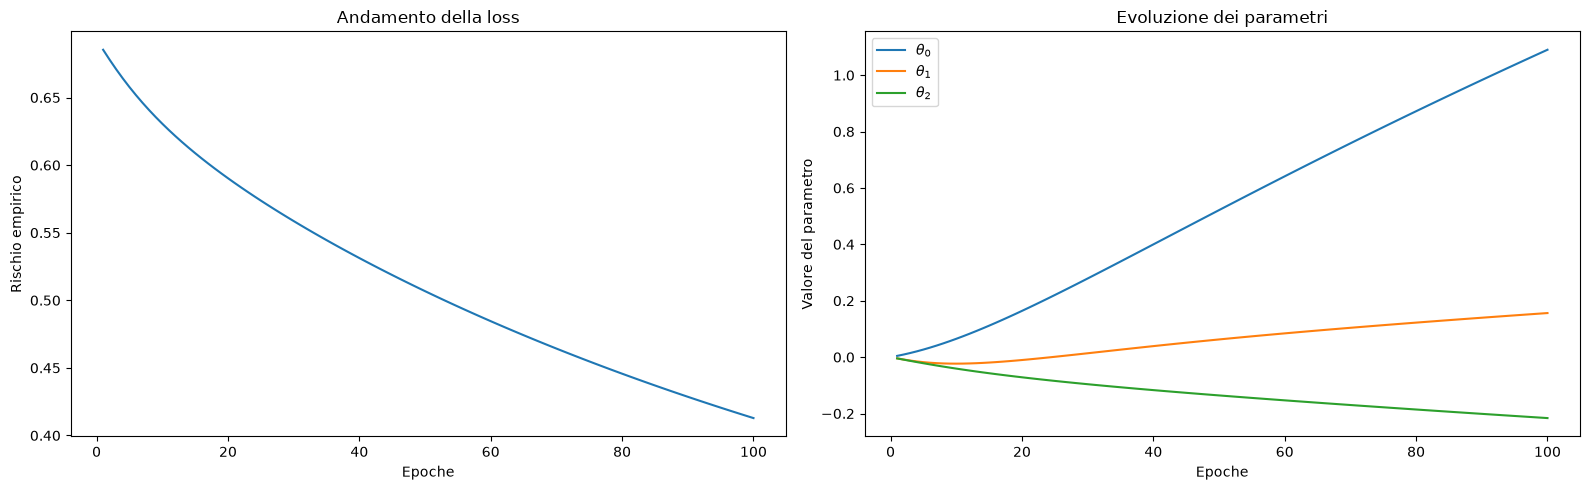

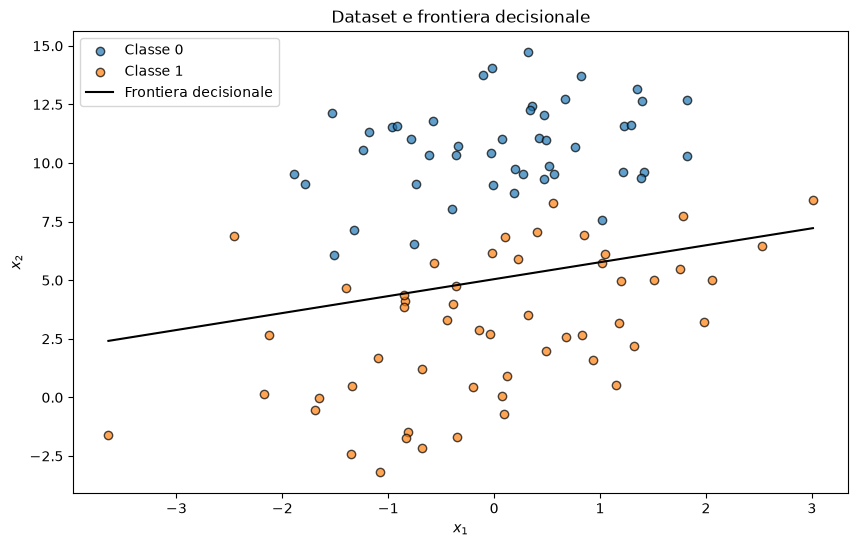


=== Adadelta (eps=1e-9) ===
Tempo: 0.0031 s
Aggiornamenti: 100
Loss finale: 0.668154
Theta finale: [ 0.02006907 -0.01251578 -0.01485107]


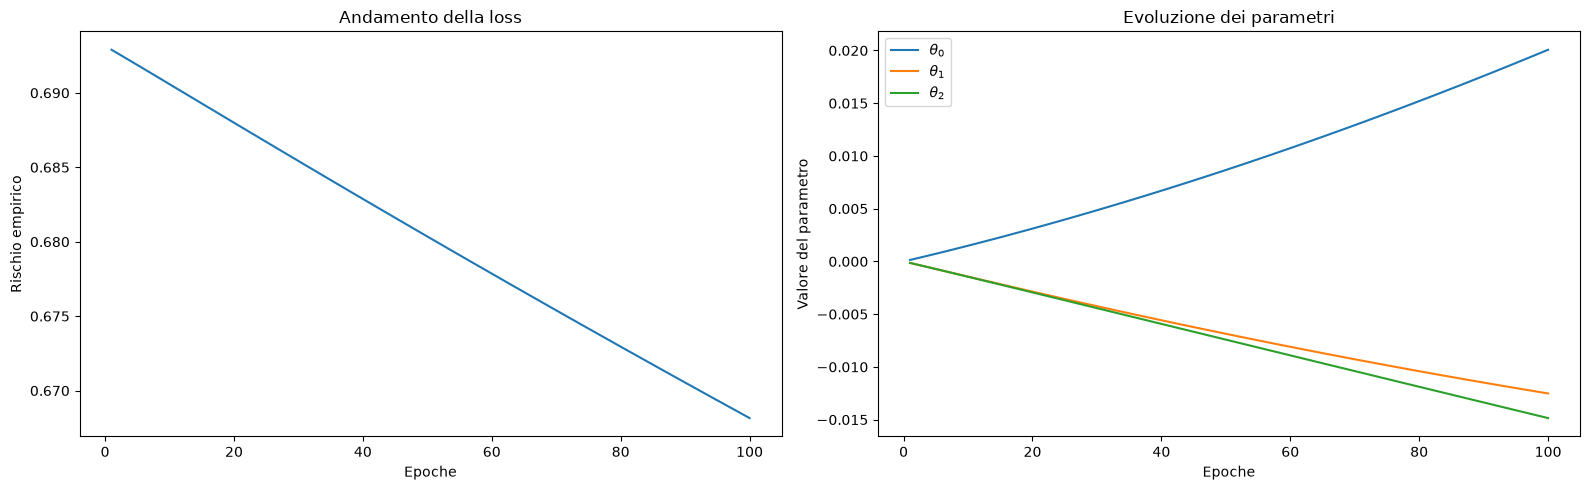

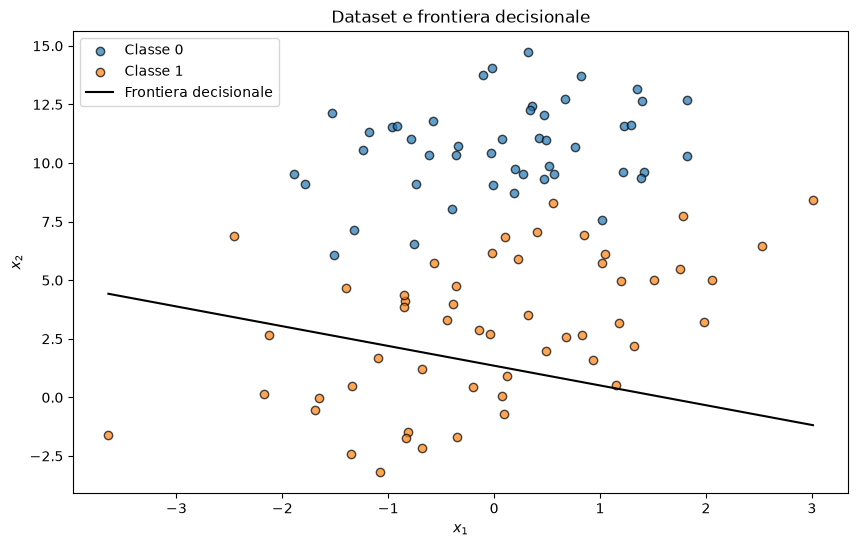

In [36]:
# ===========================================================
# ADAdelta — SENSIBILITÀ A EPSILON
# ===========================================================
# Nella nostra implementazione Adadelta non utilizza
# un learning rate globale eta esplicito.
#
# Tuttavia, il parametro eps influenza anche la
# grandezza degli aggiornamenti iniziali, perché
# G_over parte da zero.
#
# Confrontiamo due valori di eps per osservare
# quanto cambia la dinamica dell'ottimizzazione.
# ===========================================================

results["Adadelta (eps=1e-6)"] = run_optimizer(
    "Adadelta (eps=1e-6)",
    Adadelta,
    gamma=0.95,
    eps=1e-6
)

results["Adadelta (eps=1e-9)"] = run_optimizer(
    "Adadelta (eps=1e-9)",
    Adadelta,
    gamma=0.95,
    eps=1e-9
)


### ⚙️ Adam — Adaptive Moment Estimation

**Adam** (*Adaptive Moment Estimation*) è uno degli ottimizzatori più usati nel Machine Learning e nel Deep Learning.  
Unisce le idee di **Momentum** e **RMSProp**, aggiungendo una correzione iniziale per evitare stime distorte dei gradienti.

---

#### 🔹 L’idea di fondo

Adam tiene in memoria due informazioni sui gradienti:

1. una **media mobile dei gradienti** → serve a capire **la direzione media** del cambiamento (come il *momentum*);  
2. una **media mobile dei quadrati dei gradienti** → serve a capire **quanto forti** sono i gradienti (come *RMSProp*).

In breve:
- la prima aiuta a rendere il movimento più **fluido e costante**,  
- la seconda regola **automaticamente la scala del passo**.

---


#### 🔹 Le due medie mobili

Adam (*Adaptive Moment Estimation*) combina due informazioni sui gradienti:

1. una media mobile dei gradienti, che ne attenua le oscillazioni;
2. una media mobile dei quadrati dei gradienti, che ne stima la scala.

Per semplicità, in questa sezione numeriamo gli aggiornamenti da $k=1$.

Indichiamo con $g_{j,k}$ la componente $j$ del gradiente calcolato all'aggiornamento $k$.

Le due medie mobili sono:

$$
\begin{aligned}
\tilde m_{j,k}
&=
\beta_1\tilde m_{j,k-1}
+
(1-\beta_1)g_{j,k}
\\[5pt]
\tilde v_{j,k}
&=
\beta_2\tilde v_{j,k-1}
+
(1-\beta_2)g_{j,k}^2.
\end{aligned}
$$

Le condizioni iniziali sono:

$$
\tilde m_{j,0}=0,
\qquad
\tilde v_{j,0}=0.
$$

Valori tipici sono $\beta_1=0.9$ e $\beta_2=0.999$.

#### 🔹 Correzione del bias iniziale

Poiché entrambe le medie mobili partono da zero, nelle prime iterazioni sono influenzate dall'inizializzazione.

Per compensare questo effetto, Adam applica la seguente correzione:

$$
\boxed{
\begin{aligned}
\hat m_{j,k}
&=
\frac{\tilde m_{j,k}}{1-\beta_1^k}
\\[5pt]
\hat v_{j,k}
&=
\frac{\tilde v_{j,k}}{1-\beta_2^k}.
\end{aligned}
}
$$

Al primo aggiornamento:

$$
\hat m_{j,1}=g_{j,1},
\qquad
\hat v_{j,1}=g_{j,1}^2.
$$

La correzione elimina il fattore di attenuazione dovuto all'inizializzazione a zero. Non elimina, invece, la variabilità statistica dei gradienti.

#### 🔹 Aggiornamento dei parametri

Adam combina le due stime nella regola:

$$
\boxed{
\theta_j^{(k)}
=
\theta_j^{(k-1)}
-
\eta
\frac{\hat m_{j,k}}
{\sqrt{\hat v_{j,k}}+\varepsilon}
}
$$

dove:

- $\eta$ è il learning rate globale;
- $\hat m_{j,k}$ è la media mobile corretta dei gradienti;
- $\hat v_{j,k}$ è la media mobile corretta dei gradienti al quadrato;
- $\varepsilon>0$ evita divisioni per zero.

La media $\hat m_{j,k}$ determina la direzione dell'aggiornamento, mentre $\hat v_{j,k}$ ne modifica la scala per ciascun parametro.

**Nota sugli indici:** in Python il ciclo `for epoch in range(epochs)` parte da zero. Per questo il codice utilizza `k = epoch + 1` nei fattori di correzione del bias.

**Nota:** Adam non garantisce di essere più rapido o di generalizzare meglio rispetto agli altri ottimizzatori. Le prestazioni dipendono dal problema e dagli iperparametri.

---

#### 🔹 Come si comporta

- Se i gradienti sono **coerenti nel tempo**, $\hat{m}$ si accumula → il passo accelera.  
- Se i gradienti sono **molto variabili**, $\hat{v}$ cresce → il passo si riduce per stabilizzare.  

Così Adam combina la **velocità del Momentum** e la **stabilità di RMSProp**, adattandosi automaticamente.

---

#### 💡 In sintesi

| Concetto | Significato |
|-----------|-------------|
| $\tilde{m}$ | Media mobile dei gradienti (direzione media) |
| $\tilde{v}$ | Media mobile dei quadrati dei gradienti (intensità media) |
| $\beta_1, \beta_2$ | Controllano la memoria dei due momenti |
| $\hat{m}, \hat{v}$ | Versioni corrette dal bias |
| $\eta$ | Learning rate di base |
| ✅ Vantaggio | Rapido, stabile e adattivo |
| ⚠️ Limite | Troppa inerzia se i gradienti cambiano spesso direzione |

---

In breve, **Adam** funziona come un *pilota automatico intelligente*: ricorda la direzione media dei gradienti, valuta la loro intensità, e regola da solo la velocità di apprendimento per ottenere una **convergenza rapida e stabile**.


=== Adam ===
Tempo: 0.0034 s
Aggiornamenti: 100
Loss finale: 0.149895
Theta finale: [ 5.4510133   0.59543352 -0.78468587]


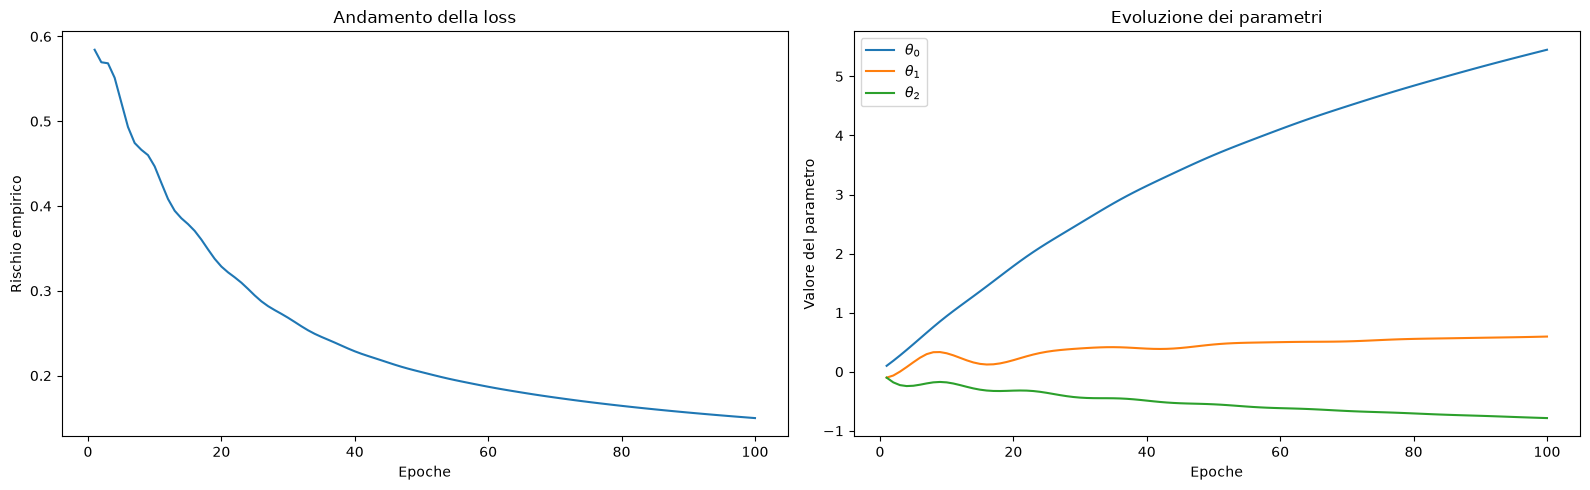

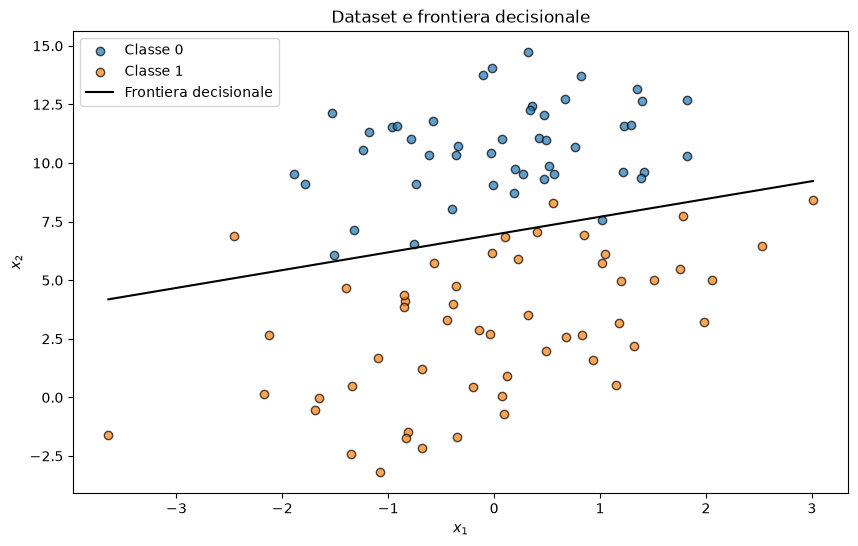

In [37]:

def Adam(X, t, eta=0.001, beta1=0.9,
         beta2=0.999, eps=1e-8, epochs=1000):
    """
    Batch Gradient Descent con Adam.

    Adam combina due idee:
    1. Momentum: memoria della direzione dei gradienti;
    2. RMSProp: adattamento della scala del passo.

    I due accumulatori sono:
    - m_tilde: primo momento, media mobile dei gradienti;
    - v_tilde: secondo momento grezzo,
               media mobile dei gradienti al quadrato.

    Entrambi vengono corretti per l'inizializzazione
    a zero prima di calcolare l'aggiornamento.
    """

    # Numero di parametri del modello.
    d = X.shape[1]

    # Parametri iniziali.
    theta = np.zeros((d, 1))

    # Primo momento:
    # memoria dei gradienti con il loro segno.
    m_tilde = np.zeros_like(theta)

    # Secondo momento grezzo:
    # memoria dei gradienti al quadrato.
    v_tilde = np.zeros_like(theta)

    cost_history, theta_history = [], []

    for epoch in range(epochs):

        # 1. Calcoliamo il gradiente batch.
        g = gradient(theta, X, t)

        # 2. PRIMO MOMENTO
        #
        #    Media mobile esponenziale dei gradienti.
        #    Conserva informazione sulla direzione
        #    dei gradienti osservati nel tempo.
        #
        #    beta1 regola la memoria del primo momento.
        m_tilde = beta1 * m_tilde + (1 - beta1) * g

        # 3. SECONDO MOMENTO GREZZO
        #
        #    Media mobile esponenziale dei quadrati.
        #    Stima la scala dei gradienti per coordinata.
        #
        #    beta2 regola la memoria del secondo momento.
        v_tilde = beta2 * v_tilde + (1 - beta2) * g**2

        # 4. CORREZIONE DEL BIAS INIZIALE
        #
        #    I due accumulatori partono da zero.
        #    Per questo, nelle prime iterazioni, le medie
        #    risultano attenuate dall'inizializzazione.
        #
        #    Il ciclo Python parte da epoch = 0, mentre
        #    le formule della bias correction contano
        #    gli aggiornamenti a partire da k = 1.
        k = epoch + 1

        # Correzione del primo momento.
        m_hat = m_tilde / (1 - beta1**k)

        # Correzione del secondo momento.
        v_hat = v_tilde / (1 - beta2**k)

        # 5. AGGIORNAMENTO DEI PARAMETRI
        #
        #    m_hat:
        #       determina la direzione dell'aggiornamento.
        #
        #    sqrt(v_hat):
        #       adatta la scala per ciascun parametro.
        #
        #    eps:
        #       evita divisioni per zero e migliora
        #       la stabilità numerica.
        #
        #    Tutte le operazioni sono elemento per elemento.
        theta -= eta * m_hat / (np.sqrt(v_hat) + eps)

        # 6. Registriamo lo stato dopo l'aggiornamento.
        theta_history.append(theta.copy())
        cost_history.append(cost(theta, X, t))

    return save_histories(cost_history, theta_history, d)


results["Adam"] = run_optimizer(
    "Adam", Adam,
    eta=0.1, beta1=0.9, beta2=0.999
)

### Metodi del secondo ordine

### ⚙️ Metodo di Newton — Ottimizzazione del secondo ordine

Finora abbiamo utilizzato metodi che sfruttano il **gradiente** per aggiornare i parametri.

Il Gradient Descent utilizza la pendenza della funzione di costo per scegliere la direzione di discesa. Il **metodo di Newton** utilizza anche un'altra informazione: **la curvatura della funzione**, descritta dalle derivate seconde.

L'obiettivo è scegliere aggiornamenti che tengano conto della geometria locale della funzione, potenzialmente riducendo il numero di iterazioni necessarie.

---

#### 🔹 1️⃣ L'idea: pendenza e curvatura

Consideriamo una funzione di costo $J(\theta)$ con un solo parametro.

Il Gradient Descent aggiorna il parametro secondo la regola:

$$
\theta^{(k+1)}=\theta^{(k)}-\eta J'(\theta^{(k)}).
$$

Il metodo di Newton utilizza invece:

$$
\boxed{
\theta^{(k+1)}
=
\theta^{(k)}
-
\frac{J'(\theta^{(k)})}{J''(\theta^{(k)})}
}
$$

La differenza è fondamentale:

- **Derivata prima $J'$:** indica la pendenza della funzione.
- **Derivata seconda $J''$:** indica quanto cambia la pendenza, cioè la curvatura.

Newton adatta lo spostamento alla curvatura locale. Se la curvatura positiva è elevata, tende a ridurre il passo; se è piccola, può proporre uno spostamento maggiore.

**Esempio:** consideriamo

$$
J(\theta)=(\theta-3)^2.
$$

Partendo da $\theta^{(0)}=0$, abbiamo $J'(0)=-6$ e $J''(0)=2$.

Newton calcola:

$$
\theta^{(1)}=0-\frac{-6}{2}=\boxed{3}.
$$

In questo caso raggiunge il minimo in un solo aggiornamento, perché la funzione è esattamente quadratica. **Non accade necessariamente per funzioni più complesse.**

---

#### 🔹 2️⃣ Più parametri: la matrice Hessiana

Nel nostro laboratorio utilizziamo la regressione logistica, con tre parametri:

$$
\theta=(\theta_0,\theta_1,\theta_2)^T.
$$

Quando i parametri sono più di uno, le derivate seconde vengono raccolte nella **matrice Hessiana**:

$$
H_{ij}(\theta)
=
\frac{\partial^2 J(\theta)}
{\partial\theta_i\partial\theta_j}.
$$

La Hessiana descrive la curvatura della funzione nelle diverse direzioni e le interazioni tra i parametri.

La formula di Newton diventa:

$$
\boxed{
\theta^{(k+1)}
=
\theta^{(k)}
-
H(\theta^{(k)})^{-1}
\nabla J(\theta^{(k)})
}
$$

In pratica, anziché calcolare esplicitamente l'inversa della Hessiana, risolviamo il sistema lineare:

$$
H(\theta^{(k)})d^{(k)}
=
\nabla J(\theta^{(k)})
$$

e aggiorniamo:

$$
\theta^{(k+1)}=\theta^{(k)}-d^{(k)}.
$$

**Attenzione:** Newton cerca un punto stazionario. Se la Hessiana non è positiva definita, la direzione calcolata non è necessariamente una direzione di discesa.

---

#### 🔹 3️⃣ La Hessiana nella regressione logistica

Nel nostro laboratorio minimizziamo il rischio empirico della regressione logistica, utilizzando la binary cross-entropy.

Il gradiente è:

$$
\nabla_\theta\hat R(\theta)
=
\frac{1}{n}X^T(p-t),
$$

dove $p$ contiene le probabilità predette dal modello.

La Hessiana ha una forma particolarmente semplice:

$$
\boxed{
H(\theta)=\frac{1}{n}X^TWX
}
$$

dove $W$ è una matrice diagonale i cui elementi sono:

$$
W_{ii}=p_i(1-p_i).
$$

Il fattore $p_i(1-p_i)$ misura il contributo di ciascun esempio alla curvatura della funzione:

- se $p_i=0.5$, il contributo è massimo: $0.25$;
- se $p_i$ è vicino a $0$ oppure a $1$, il contributo è più piccolo.

Poiché questi valori sono sempre non negativi, la Hessiana è **semidefinita positiva**: la funzione di costo della regressione logistica è convessa nei parametri.

Nel codice, la funzione `hessian()` calcola questa matrice senza costruire esplicitamente $W$, utilizzando le operazioni matriciali di NumPy.

---

#### 🔹 4️⃣ Newton nel nostro laboratorio: stabilizzazione e backtracking

La nostra implementazione introduce due accorgimenti per rendere gli aggiornamenti più affidabili.

**1. Stabilizzazione della Hessiana**

Aggiungiamo un piccolo valore positivo alla diagonale:

$$
H_{\mathrm{reg}}=H+\lambda I.
$$

Questo migliora il condizionamento della matrice e, nel nostro problema convesso, la rende positiva definita per $\lambda>0$.

Nel codice:

`H_reg = H + damping * np.eye(d)`

La direzione viene calcolata risolvendo:

$$
H_{\mathrm{reg}}d=g.
$$

Nel codice:

`direction = np.linalg.solve(H_reg, g)`

**2. Backtracking line search**

La direzione di Newton può suggerire un passo troppo grande. Per questo non aggiorniamo immediatamente i parametri.

Partiamo da un passo $\alpha=1$ e proviamo:

$$
\theta_{\mathrm{candidate}}=\theta-\alpha d.
$$

Se la funzione di costo diminuisce, accettiamo il candidato. Altrimenti dimezziamo $\alpha$ e riproviamo.

Nel codice:

`candidate = theta - step * direction`

`step *= 0.5`

In questo modo **la direzione viene scelta usando gradiente e curvatura**, mentre il backtracking controlla che lo spostamento effettivo riduca la loss.

---

#### 💡 In sintesi

| Metodo | Informazione utilizzata | Aggiornamento |
|---|---|---|
| **Gradient Descent** | Gradiente | Passo nella direzione opposta alla pendenza |
| **Newton** | Gradiente e Hessiana | Passo corretto in base alla curvatura |

Newton può raggiungere una soluzione in meno iterazioni, ma ogni aggiornamento è più costoso: richiede di calcolare la Hessiana e risolvere un sistema lineare.

Nel nostro esempio di regressione logistica abbiamo soltanto **tre parametri**, quindi questi calcoli sono semplici. In modelli con milioni di parametri, invece, possono diventare proibitivi.

**Messaggio fondamentale:** Newton non è semplicemente un Gradient Descent più veloce. È un metodo che utilizza informazioni di secondo ordine per adattare gli aggiornamenti alla curvatura della funzione di costo.

Newton: gradiente piccolo al passo 8.

=== Newton ===
Tempo: 0.0015 s
Aggiornamenti: 8
Loss finale: 0.093158
Theta finale: [14.75209566  1.25357975 -2.00266562]


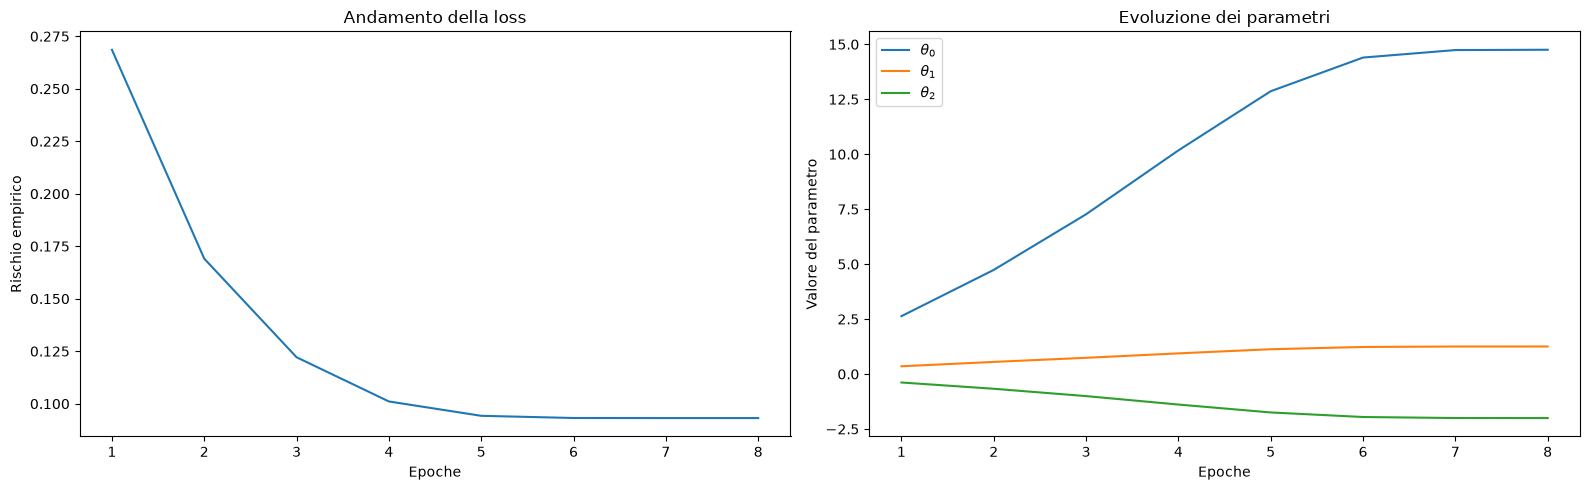

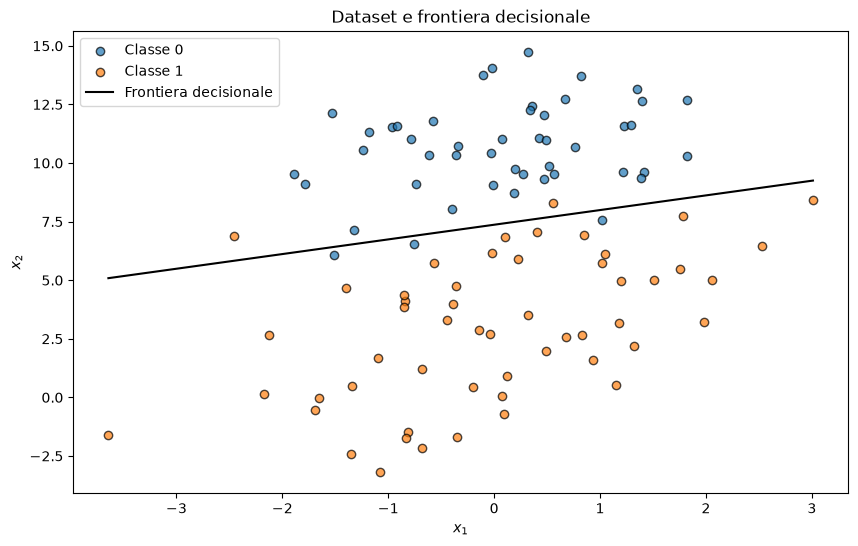

In [38]:

def hessian(theta, X):
    """
    Calcola la matrice Hessiana del rischio empirico
    per la regressione logistica.

    H(theta) = X.T @ W @ X / n

    dove W è una matrice diagonale con elementi
    p_i * (1 - p_i), e p_i è la probabilità
    stimata dal modello per l'esempio i.

    La versione implementata evita di costruire
    esplicitamente la matrice diagonale W.
    """

    # 1. Probabilità predette per tutti gli esempi.
    p = f(theta, X)

    # 2. Ogni esempio contribuisce alla Hessiana
    #    con un peso p_i * (1 - p_i).
    #
    #    .ravel() trasforma il vettore colonna
    #    in un array monodimensionale.
    weights = (p * (1 - p)).ravel()

    # 3. Moltiplichiamo ciascuna riga di X per
    #    il peso corrispondente.
    #
    #    weights[:, None] crea una colonna,
    #    rendendo possibile il broadcasting NumPy.
    #
    #    E' equivalente a costruire X.T @ W @ X,
    #    ma evita di allocare la matrice diagonale W.
    return X.T @ (X * weights[:, None]) / len(X)


def newton(X, t, epochs=100, tol=1e-6,
           damping=1e-6):
    """
    Metodo di Newton per la regressione logistica.

    A ogni iterazione:
    1. calcola il gradiente;
    2. calcola la Hessiana;
    3. regolarizza la Hessiana;
    4. risolve un sistema lineare;
    5. cerca un passo che riduca la loss.

    L'algoritmo può terminare prima di epochs.
    """

    d = X.shape[1]
    theta = np.zeros((d, 1))

    cost_history, theta_history = [], []

    for epoch in range(epochs):

        # 1. Calcoliamo il gradiente del rischio empirico.
        g = gradient(theta, X, t)

        # 2. CRITERIO DI ARRESTO
        #
        #    In un punto stazionario il gradiente è zero.
        #    Se la sua norma è sufficientemente piccola,
        #    interrompiamo l'ottimizzazione.
        #
        #    La condizione viene controllata PRIMA
        #    di calcolare il nuovo aggiornamento.
        if np.linalg.norm(g) < tol:
            print(f"Newton: gradiente piccolo al passo {epoch}.")
            break

        # 3. Calcoliamo la matrice delle derivate seconde.
        H = hessian(theta, X)

        # 4. REGOLARIZZAZIONE DELLA HESSIANA
        #
        #    Aggiungiamo damping * I alla Hessiana.
        #
        #    I è la matrice identità d x d.
        #    Questo termine migliora il condizionamento
        #    del sistema e rende positiva definita
        #    la matrice regolarizzata in questa applicazione
        #    di regressione logistica, per damping > 0.
        H_reg = H + damping * np.eye(d)

        # 5. DIREZIONE DI NEWTON
        #
        #    Risolviamo il sistema:
        #
        #        H_reg @ direction = g
        #
        #    La direzione di aggiornamento sarà
        #    -direction.
        #
        #    np.linalg.solve risolve direttamente
        #    il sistema lineare, senza calcolare
        #    esplicitamente l'inversa della matrice.
        direction = np.linalg.solve(H_reg, g)

        # 6. BACKTRACKING LINE SEARCH
        #
        #    Il passo pieno di Newton corrisponde
        #    inizialmente a step = 1.
        #
        #    Non assumiamo però che tale passo
        #    diminuisca sempre la loss.
        old_cost = cost(theta, X, t)
        step = 1.0

        # Riduciamo progressivamente il passo
        # finché troviamo un aggiornamento migliorativo.
        while step > 1e-8:

            # Parametri candidati dopo il passo.
            candidate = theta - step * direction

            # Se la loss diminuisce, accettiamo
            # il valore corrente di step.
            if cost(candidate, X, t) < old_cost:
                break

            # Altrimenti dimezziamo il passo.
            step *= 0.5

        # Se non troviamo un passo sufficientemente
        # piccolo che migliori la loss, ci fermiamo.
        if step <= 1e-8:
            print("Newton: nessun passo migliorativo trovato.")
            break

        # 7. Aggiorniamo i parametri con il passo accettato.
        theta = candidate

        # 8. Salviamo i risultati.
        theta_history.append(theta.copy())
        cost_history.append(cost(theta, X, t))

    return save_histories(cost_history, theta_history, d)


results["Newton"] = run_optimizer(
    "Newton", newton,
    tol=1e-6
)


### ⚠️ Una precisazione sulla convergenza della regressione logistica

Gli ottimizzatori implementati minimizzano il rischio empirico della regressione logistica, senza un termine esplicito di regolarizzazione:

$$
\hat R(\theta)
=
-\frac1n\sum_{i=1}^n
\left[
t_i\log p_i+(1-t_i)\log(1-p_i)
\right],
$$

dove $p_i=\sigma(x_i^\top\theta)$.

Se il dataset è linearmente separabile, può accadere che

$$
\inf_\theta \hat R(\theta)=0,
$$

ma che tale valore non sia raggiunto da alcun vettore finito di parametri.

Infatti, aumentando progressivamente la norma dei coefficienti lungo una direzione che separa correttamente le classi, le probabilità possono avvicinarsi sempre più a $0$ e $1$ e la loss può continuare a diminuire.

Questo significa che:

- una loss molto piccola non implica necessariamente che i parametri si siano stabilizzati;
- un gradiente piccolo non garantisce sempre l'esistenza di un minimizzatore finito;
- metodi differenti possono raggiungere rapidamente un'elevata accuracy, pur continuando a produrre parametri di grandezza diversa.

**Obiettivo del laboratorio:** osservare la dinamica degli ottimizzatori, non dimostrare che ogni esecuzione raggiunga un minimo finito.

Una possibile estensione consiste nell'aggiungere una regolarizzazione $L_2$.


## 📊 Valutazione delle prestazioni dei metodi di ottimizzazione

Abbiamo implementato diversi **ottimizzatori avanzati** — come Momentum, Nesterov, Adagrad, RMSProp, Adadelta, Adam e Newton-Raphson — e osservato il loro comportamento in termini di convergenza e stabilità.  
Ora vogliamo rispondere alla domanda fondamentale: **quanto bene predicono?**

Per valutarlo, misuriamo l’**accuratezza finale di classificazione** dei modelli ottenuti da ciascun metodo, utilizzando i parametri finali $\theta$ per predire le etichette del dataset e confrontarle con i valori reali.

⚠️ **Attenzione:** in questa fase stiamo **valutando le prestazioni sullo stesso dataset usato per l’addestramento**.  
Questo significa che i risultati potrebbero essere **ottimistici**, perché non misurano la capacità del modello di generalizzare su dati nuovi.  

In un contesto reale, per una valutazione corretta dovremmo usare:
- un **validation set** (insieme di dati separato), oppure  
- una **cross-validation** per stimare le prestazioni su dati non visti.

In questo laboratorio, tuttavia, l’obiettivo è **confrontare gli ottimizzatori tra loro**, verificando quanto rapidamente e accuratamente riescono a minimizzare il rischio empirico sul dataset di training.

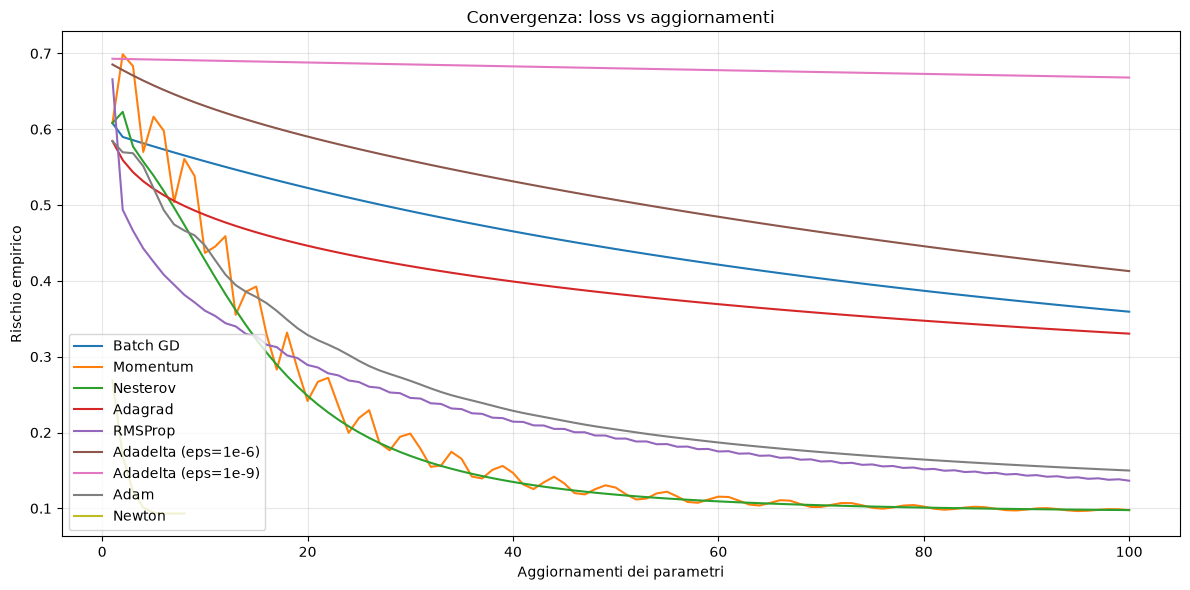

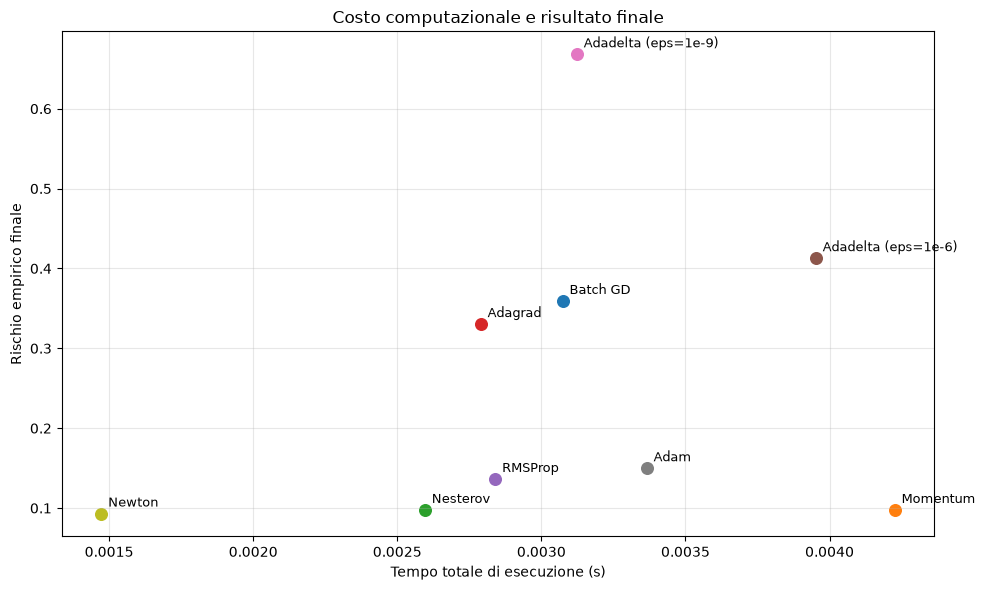

In [39]:
# ===========================================================
# CONFRONTO FINALE DEGLI OTTIMIZZATORI
# ===========================================================
# Grafico 1: rischio empirico vs aggiornamenti
# Grafico 2: rischio finale vs tempo totale
#
# ATTENZIONE:
# Il numero di aggiornamenti non misura da solo il
# costo computazionale, soprattutto per Newton.
# ===========================================================

# -----------------------------------------------------------
# GRAFICO 1 — LOSS VS AGGIORNAMENTI
# -----------------------------------------------------------

plt.figure(figsize=(12, 6))

for name, result in results.items():

    costs = result["cost_history"].ravel()
    steps = np.arange(1, len(costs) + 1)

    plt.plot(steps, costs, label=name)

plt.xlabel("Aggiornamenti dei parametri")
plt.ylabel("Rischio empirico")
plt.title("Convergenza: loss vs aggiornamenti")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# -----------------------------------------------------------
# GRAFICO 2 — LOSS FINALE VS TEMPO TOTALE
# -----------------------------------------------------------

plt.figure(figsize=(10, 6))

for name, result in results.items():

    elapsed = result["time"]
    final_cost = result["cost_history"][-1, 0]

    plt.scatter(elapsed, final_cost, s=70)
    plt.annotate(
        name,
        (elapsed, final_cost),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

plt.xlabel("Tempo totale di esecuzione (s)")
plt.ylabel("Rischio empirico finale")
plt.title("Costo computazionale e risultato finale")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 📘 Riepilogo — Metodi di Ottimizzazione Avanzata

In questo laboratorio abbiamo confrontato diverse varianti del **gradient descent**,  
ognuna progettata per migliorare la **velocità**, la **stabilità** o la **robustezza** della convergenza.



### 📊 Confronto qualitativo

| Metodo | Informazione utilizzata | Idea fondamentale | Principale limite |
|---|---|---|---|
| Gradient Descent | Gradiente corrente | Passo opposto al gradiente | Sensibilità al learning rate |
| Momentum | Gradiente corrente e aggiornamenti passati | Accumula velocità nelle direzioni coerenti | Possibili oscillazioni e overshooting |
| Nesterov | Momentum e gradiente anticipato | Calcola il gradiente nel punto look-ahead | Richiede una scelta adeguata di $\eta$ e $\gamma$ |
| Adagrad | Somma cumulativa dei quadrati dei gradienti | Adatta il passo per ogni parametro | Riduzione monotona del learning rate effettivo |
| RMSProp | Media mobile dei quadrati dei gradienti | Adattamento basato sui gradienti recenti | Sensibilità agli iperparametri |
| Adadelta | Medie mobili dei gradienti e degli incrementi | Adatta la scala dei passi senza un $\eta$ esplicito | Prestazioni dipendenti da $\gamma$ ed $\varepsilon$ |
| Adam | Medie mobili dei gradienti e dei loro quadrati | Combina momentum e adattamento per coordinata | Non sempre offre la migliore convergenza o generalizzazione |
| Newton | Gradiente e Hessiana | Utilizza la curvatura locale della funzione | Costo computazionale e memoria elevati |

### 💬 Conclusione

Gli ottimizzatori differiscono per le informazioni utilizzate e per la regola con cui aggiornano i parametri:

- **Momentum e Nesterov** utilizzano la storia degli aggiornamenti.
- **Adagrad, RMSProp e Adadelta** adattano il passo per ciascun parametro.
- **Adam** combina la media mobile dei gradienti con quella dei loro quadrati.
- **Newton** sfrutta anche la curvatura della funzione obiettivo.

Non esiste un ottimizzatore universalmente migliore.

La scelta dipende dalla funzione obiettivo, dalle dimensioni del problema, dagli iperparametri e dalle risorse computazionali disponibili.

**Obiettivo del laboratorio:** comprendere come cambia la dinamica dell'ottimizzazione quando modifichiamo la regola di aggiornamento dei parametri.



### 🧩 Esercizio — Criteri di arresto e confronto delle prestazioni

Finora gli ottimizzatori sono stati eseguiti per un numero massimo prefissato di aggiornamenti, controllato da `epochs`.

In un'applicazione reale, però, può essere utile interrompere l'ottimizzazione quando i miglioramenti diventano molto piccoli.

#### 🎯 Obiettivo

Modificare uno degli ottimizzatori, ad esempio Momentum oppure Adam, introducendo un criterio di arresto automatico.

Si possono considerare tre criteri.

**1. Variazione della loss**

Interrompere se

$$
|\hat R(\theta^{(k+1)})-\hat R(\theta^{(k)})|<\varepsilon.
$$

**2. Variazione dei parametri**

Interrompere se

$$
\|\theta^{(k+1)}-\theta^{(k)}\|_2<\varepsilon.
$$

**3. Norma del gradiente**

Interrompere se

$$
\|\nabla_\theta\hat R(\theta^{(k)})\|_2<\varepsilon.
$$

#### ⚠️ Attenzione

Un criterio di arresto indica che è stata soddisfatta una condizione numerica, **non necessariamente che sia stato raggiunto il minimo globale**.

Per esempio, una piccola variazione dei parametri può dipendere da un learning rate molto piccolo.

#### 🔬 Attività

1. Scegliere un ottimizzatore e implementare almeno un criterio di arresto.
2. Utilizzare `epochs` come numero massimo di aggiornamenti consentiti.
3. Confrontare l'esecuzione con e senza arresto automatico.
4. Misurare il numero di aggiornamenti, il tempo di esecuzione, il rischio empirico finale e l'accuracy sul training set.
5. Ripetere l'esperimento utilizzando soglie diverse, ad esempio `1e-4`, `1e-6` e `1e-8`.

#### 💬 Domande finali

- Un criterio molto permissivo può interrompere l'algoritmo troppo presto?
- Un learning rate molto piccolo può far apparire convergente un algoritmo?
- Due metodi con accuracy simile possono avere cross-entropy molto differenti?
- Qual è il rapporto tra numero di aggiornamenti e tempo di esecuzione?

**Conclusione:** la convergenza numerica, il costo computazionale e la qualità predittiva sono aspetti distinti e devono essere valutati separatamente.
